# DC4 original mock: 19-parameter true-energy BinnedSED fit

Fit the original three-month, NGC 4151-GTI full mock with COSIpy's standard
`BinnedThreeMLModelFolding` → `PoissonLikelihood` → `ThreeMLPluginInterface`
flow and threeML's SciPy L-BFGS-B minimizer. NGC 4151 has a free cutoff
power law (K, index, cutoff). Crab, MAXI J1820+070, and the 4C+21.35
flare each have five free **true photon-energy** `BinnedSED` normalizations
below 1 MeV. One instrumental background rate completes the 19 free
parameters.

The fixed catalog sky is folded once and included as a **fixed count
template** in the background interface. For the three fitted nuisance
sources, validated per-Ei response templates are supplied through COSIpy's
source-specific response interface. This avoids repeating the expensive
response calculation at every optimizer trial. `DIRECT_FOLDING=True` in the
fit cell instead uses the direct weighted point-source responses; it is
scientifically equivalent but much slower. Neither mode uses a custom
threeML likelihood plugin.

Crab keeps four spectral and temporal components, linked to one fitted
scale per true-energy bin. Other catalog sources and the high-energy bins
stay fixed. Input data and background histograms already have the NGC 4151
GTI. Run cells top to bottom in a fresh kernel. Previous custom-likelihood
results remain in their separate JSON file for comparison.


In [1]:
from pathlib import Path
from copy import deepcopy
import gc
import hashlib
import json
import sys

import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display
from scipy.special import xlogy

from astromodels import (
    Cutoff_powerlaw, Line, Model, Parameter, PointSource, SpectralComponent,
)
from histpy import Histogram
from threeML import DataList, JointLikelihood, PluginPrototype
from threeML.minimizer.minimization import FitFailed, LocalMinimization

from cosipy.background_estimation import FreeNormBinnedBackground
from cosipy.data_io import EmCDSBinnedData
from cosipy.event_selection import GoodTimeInterval
from cosipy.response import (
    BinnedInstrumentResponse, BinnedThreeMLModelFolding,
    BinnedThreeMLPointSourceResponse, BinnedThreeMLExtendedSourceResponse,
    ExtendedSourceResponse,
)
from cosipy.response.FullDetectorResponse import FullDetectorResponse
from cosipy.response.temporal_profile import LightcurveProfile
from cosipy.response.threeml_temporal_response import (
    ComponentPointSourceResponse, make_weighted_point_source_response,
)
from cosipy.spacecraftfile import SpacecraftHistory
from cosipy.threeml import BinnedSED
from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401
from cosipy.util.megalib import megalib_map_to_galprop_fits

08:40:56 WARNING   The naima package is not available. Models that depend on it will not be         ]8;id=312940;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=302436;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#43\43]8;;\
                  available                                                                                        

WARNING   The GSL library or the pygsl wrapper cannot be loaded. Models that depend on it  ]8;id=202632;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py\functions.py]8;;\:]8;id=653348;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/functions.py#65\65]8;;\
                  will not be available.                                                                           

08:40:57 WARNING   The ebltable package is not available. Models that depend on it will not be     ]8;id=691009;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py\absorption.py]8;;\:]8;id=776875;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/functions/functions_1D/absorption.py#33\33]8;;\
                  available                                                                                        

08:40:57 INFO      Starting 3ML!                                                                     ]8;id=494745;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=953943;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#44\44]8;;\

WARNING   WARNINGs here are NOT errors                                                      ]8;id=908395;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=825132;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#45\45]8;;\

WARNING   but are inform you about optional packages that can be installed                  ]8;id=394298;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=758764;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#46\46]8;;\

... (5 outputs left out)

08:40:58 WARNING   No fermitools installed                                              ]8;id=399452;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py\lat_transient_builder.py]8;;\:]8;id=744219;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/utils/data_builders/fermi/lat_transient_builder.py#44\44]8;;\

WARNING   Env. variable OMP_NUM_THREADS is not set. Please set it to 1 for optimal         ]8;id=642313;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=535127;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#335\335]8;;\
                  performances in 3ML                                                                              

WARNING   Env. variable MKL_NUM_THREADS is not set. Please set it to 1 for optimal         ]8;id=152118;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=603275;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#335\335]8;;\
                  performances in 3ML                                                                              

WARNING   Env. variable NUMEXPR_NUM_THREADS is not set. Please set it to 1 for optimal     ]8;id=71067;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py\__init__.py]8;;\:]8;id=510211;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/__init__.py#335\335]8;;\
                  performances in 3ML                                                                              

## Catalog and response helpers

These setup helpers are copied from the original notebook so this fit can
run independently. They validate the temporal-response recipe, relocate
source-library assets, and preserve the injected spatial templates.

In [2]:
def load_recipe(path, catalog_path, model):
    # A relocated recipe may be supplied in memory; retain the same validation.
    recipe = deepcopy(path) if isinstance(path, dict) else json.loads(Path(path).read_text())
    if recipe.get('schema') != 'dc4-component-lightcurve-response-v1':
        raise ValueError("Unsupported temporal-response recipe schema")
    if Path(recipe['catalog']).resolve() != Path(catalog_path).resolve():
        raise ValueError("The response recipe belongs to a different catalog")
    if recipe['selection'] not in {'full', 'NGC4151_GTI'} or recipe['time_basis'] != 'elapsed':
        raise ValueError("Expected a full-observation or NGC4151 GTI elapsed-time catalog")
    if set(row['source'] for row in recipe['components']) != set(model.sources):
        raise ValueError("Recipe and catalog source lists differ")
    if any(row['selection'] != recipe['selection'] for row in recipe['components']):
        raise ValueError("Mixed selections in response recipe")
    keys = [(r['source'], r['component']) for r in recipe['components']]
    if len(set(keys)) != len(keys):
        raise ValueError("Duplicate source/component recipe entries")
    return recipe


def component_name(source, label):
    if label in source.components:
        return label
    # v1 recipes store MEGAlib labels rather than astromodels component names.
    crab_names = {'Crab_Nebula': 'nebula', 'Crab_P1': 'peak1',
                  'Crab_Brg': 'bridge', 'Crab_P2': 'peak2'}
    if source.name == 'crab' and crab_names.get(label) in source.components:
        return crab_names[label]
    raise ValueError(f"Unknown temporal component {source.name}/{label}")


def make_temporal_responses(model, recipe, base_history, gti, data,
                            instrument_response, detector_response,
                            exposure_multiplier=1., full_history=None):
    """Build per-source/component responses from the unscaled GTI history.

    Validate temporal factors over the CATALOG selection, which can differ
    from the analysis GTI. Full catalogs require the original full_history:
    response weights remain L(t)/mean_full while exposure is GTI restricted.
    Exposure repetitions multiply response livetimes, not fluxes.
    Responses are computed lazily by cosipy and reused throughout fitting.
    """
    if not np.isfinite(exposure_multiplier) or exposure_multiplier <= 0:
        raise ValueError("Exposure multiplier must be finite and positive")
    starts, stops = np.asarray(gti.tstart_list.unix), np.asarray(gti.tstop_list.unix)
    duration = float(np.sum(stops-starts))
    if duration <= 0 or np.any(stops <= starts):
        raise ValueError("The analysis GTI must have positive duration")
    catalog_selection = recipe.get('selection', 'NGC4151_GTI')
    if catalog_selection == 'full':
        if full_history is None:
            raise ValueError("Full-observation catalogs require the original full_history")
        reference_starts = np.array([full_history.obstime[0].unix])
        reference_stops = np.array([full_history.obstime[-1].unix])
        if np.any(starts < reference_starts[0]-1e-5) or np.any(stops > reference_stops[0]+1e-5):
            raise ValueError("The analysis GTI extends beyond the catalog observation")
    elif catalog_selection == 'NGC4151_GTI':
        reference_starts, reference_stops = starts, stops
    else:
        raise ValueError(f"Unsupported catalog selection: {catalog_selection}")
    reference_duration = float(np.sum(reference_stops-reference_starts))
    if not np.isfinite(reference_duration) or reference_duration <= 0:
        raise ValueError("Invalid catalog reference duration")
    history_starts, history_stops = base_history.intervals_tstart.unix, base_history.intervals_tstop.unix
    rows_by_source = {}
    for row in recipe['components']:
        rows_by_source.setdefault(row['source'], []).append(row)
    overrides, diagnostics = {}, []
    for key, rows in rows_by_source.items():
        source = model.sources[key]
        for row in rows:
            if not np.isclose(row['selected seconds'], reference_duration, rtol=0., atol=1e-4):
                raise ValueError(f"Reference duration differs from the catalog: {key}")
        if not any(row['lightcurve'] for row in rows):
            continue
        if not isinstance(source, PointSource):
            raise NotImplementedError(f"A temporal extended response is required for {key}")
        if any(r['component'] == 'all' for r in rows) and len(rows) != 1:
            raise ValueError(f"Invalid component grouping for {key}")
        component_responses = {}
        for row in rows:
            applied = float(row['applied factor'])
            if not np.isfinite(applied) or applied <= 0:
                raise ValueError(f"Invalid applied factor for {key}")
            if row['lightcurve']:
                profile = LightcurveProfile.from_dat(
                    row['lightcurve'], expected_sha256=row['lightcurve sha256'],
                    repeating=row['repeating'], mode=row['normalization mode'],
                    bins=int(row['simulation bins']),
                )
                mean = float(profile.integral(reference_starts, reference_stops).sum()/reference_duration)
                gti_mean = float(profile.integral(starts, stops).sum()/duration)
                weights = profile.response_weights(history_starts, history_stops, applied)
                del profile
            else:
                mean, gti_mean, weights = 1., 1., np.ones(base_history.nintervals)
            if not np.isclose(mean, row['time factor'], rtol=1e-8, atol=1e-14):
                raise ValueError(f"Temporal factor differs from catalog for {key}/{row['component']}")
            if not np.isclose(applied, max(mean, 1e-30), rtol=1e-8, atol=0.):
                raise ValueError(f"Applied factor differs from catalog for {key}")
            weighted_live = base_history.livetime * weights * exposure_multiplier
            response = make_weighted_point_source_response(
                base_history, weights, data, instrument_response, detector_response,
                exposure_multiplier=exposure_multiplier,
            )
            diagnostics.append({'source': key, 'component': row['component'],
                                'normalization mode': row['normalization mode'],
                                'simulation bins': row['simulation bins'],
                                'catalog selection': catalog_selection,
                                'catalog time factor': mean,
                                'analysis GTI time factor': gti_mean,
                                'response denominator': applied,
                                'weighted response seconds': float(weighted_live.to_value(u.s).sum())})
            if row['component'] == 'all':
                overrides[key] = response
            else:
                name = component_name(source, row['component'])
                if name in component_responses:
                    raise ValueError(f"Duplicate mapped component for {key}/{name}")
                component_responses[name] = response
        if component_responses:
            if set(component_responses) != set(source.components):
                raise ValueError(f"Recipe does not cover all components of {key}")
            overrides[key] = ComponentPointSourceResponse(component_responses)
    return overrides, diagnostics

In [3]:
SPATIAL_TEMPLATE_NSIDE = 8
SPATIAL_TEMPLATE_FORMAT_TAG = "perMeV_v3"
SPATIAL_DEFINITIONS = {'positrons_26al_line': ('DC3', 'Positrons_from_26Al_line'),
 'positrons_26al_cont': ('DC3', 'Positrons_from_26Al_cont'),
 'positrons_44ti_line': ('DC3', 'Positrons_from_44Ti_line'),
 'positrons_44ti_cont': ('DC3', 'Positrons_from_44Ti_cont'),
 'narrow_bulge_511': ('DC3', 'NB_511'),
 'broad_bulge_511': ('DC3', 'BB_511'),
 'vela_snr_511': ('DC3', 'Vela_SNR_511'),
 'al26_ne2001': ('DC3', '26Al_NE2001'),
 'fe60_ne2001': ('DC3', '60Fe_NE2001'),
 'positrons_thin_disk_cont': ('DC4', 'Positrons_Thin_Disk_cont'),
 'positrons_thin_disk_line': ('DC4', 'Positrons_Thin_Disk_line')}

def resolve_source_asset(source_definition, filename):
    path = source_definition.parent / filename
    candidates = [path, Path(f"{path}.gz")]
    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()
    raise FileNotFoundError(
        f"Could not resolve {filename!r} next to {source_definition}"
    )


def parse_megalib_blocks(source_definition):
    # Return one property dictionary per DataChallenge.Source block.
    blocks = []
    by_megalib_name = {}
    for raw_line in source_definition.read_text().splitlines():
        line = raw_line.split("#", 1)[0].strip()
        if not line:
            continue
        tokens = line.split()
        if tokens[:1] == ["DataChallenge.Source"]:
            megalib_name = tokens[1]
            block = {"_name": megalib_name}
            blocks.append(block)
            by_megalib_name[megalib_name] = block
            continue
        if "." not in tokens[0]:
            continue
        megalib_name, prop = tokens[0].split(".", 1)
        if megalib_name in by_megalib_name:
            by_megalib_name[megalib_name][prop] = tokens[1:]
    if not blocks:
        raise ValueError(f"No DataChallenge.Source blocks in {source_definition}")
    return blocks


def source_library_path(value, source_library):
    """Relocate a catalog asset without relying on the original user's home."""
    parts = Path(value).parts
    if "Source_Library" not in parts:
        raise ValueError(f"Not a source-library path: {value}")
    relative = Path(*parts[parts.index("Source_Library") + 1:])
    candidate = (Path(source_library) / relative).resolve()
    if not candidate.is_file():
        raise FileNotFoundError(candidate)
    return str(candidate)


def ensure_spatial_template(source_name, output_path, source_library, overwrite=False):
    """Build only missing templates, preserving the generator's conversion."""
    output_path = Path(output_path)
    if output_path.exists() and not overwrite:
        with fits.open(output_path) as hdul:
            if (hdul['SKYMAP'].header.get('NSIDE') != SPATIAL_TEMPLATE_NSIDE
                    or hdul['SKYMAP'].header.get('MAPVERS') != SPATIAL_TEMPLATE_FORMAT_TAG):
                raise ValueError(f"Incompatible cached spatial template: {output_path}")
        return output_path, 'loaded'
    challenge, stem = SPATIAL_DEFINITIONS[source_name]
    matches = sorted((Path(source_library) / challenge / 'sources').rglob(f'{stem}.source'))
    if len(matches) != 1:
        raise ValueError(f"Expected one {stem}.source, found {matches}")
    blocks = parse_megalib_blocks(matches[0])
    if len(blocks) != 1 or len(blocks[0].get('Beam', [])) < 2:
        raise ValueError(f"Expected one coupled map in {matches[0]}")
    map_path = resolve_source_asset(matches[0], blocks[0]['Beam'][1])
    megalib_map_to_galprop_fits(
        map_path, output_path, nside=SPATIAL_TEMPLATE_NSIDE,
        oversample_nside=64, energy_bounds=(100., 10000.), overwrite=overwrite,
    )
    return output_path, 'created'


def prepare_catalog(catalog_path, recipe_input, source_library, template_directory,
                    orientation_path, response_path, binning_path, overwrite=False):
    """Generate templates, relocate external assets, and load without rewriting YAML.

    The YAML and base JSON remain byte-for-byte unchanged. Only
    the in-memory dictionaries receive this computer's paths. Their source
    amplitudes and the recipe's light-curve hashes are never modified.
    """
    from astromodels.core.model_parser import ModelParser
    from cosipy.threeml.custom_functions import GalpropHealpixModel, SpecFromDat  # noqa: F401

    catalog_path = Path(catalog_path)
    contents = yaml.safe_load(catalog_path.read_text())
    recipe = deepcopy(recipe_input)
    if Path(recipe['catalog']).name != catalog_path.name:
        raise ValueError('The recipe refers to a different catalog filename')
    recipe['catalog'] = str(catalog_path.resolve())
    for key, local in [('orientation', orientation_path), ('detector_response', response_path),
                       ('binning', binning_path)]:
        if Path(recipe[key]).name != Path(local).name:
            raise ValueError(f'{key} filename differs from the catalog recipe')
        recipe[key] = str(Path(local).resolve())
    for row in recipe['components']:
        if row['lightcurve']:
            row['lightcurve'] = source_library_path(row['lightcurve'], source_library)

    template_rows = []
    def relocate(node, source_name):
        if isinstance(node, dict):
            for key, value in node.items():
                if key == '_fitsfile' and value:
                    expected_name = f'{source_name}_nside8_perMeV_v3.fits'
                    if Path(value).name != expected_name:
                        raise ValueError(f'Unsupported spatial template: {value}')
                    path, status = ensure_spatial_template(
                        source_name, Path(template_directory) / expected_name,
                        source_library, overwrite=overwrite,
                    )
                    node[key] = str(path.resolve())
                    template_rows.append({'source': source_name, 'status': status, 'file': str(path)})
                elif isinstance(value, str) and 'Source_Library/' in value:
                    node[key] = source_library_path(value, source_library)
                else:
                    relocate(value, source_name)
        elif isinstance(node, list):
            for value in node:
                relocate(value, source_name)
    for source_key, definition in contents.items():
        relocate(definition, source_key.split(' (')[0])
    model = ModelParser(model_dict=contents).get_model()
    recipe = load_recipe(recipe, catalog_path, model)
    return model, recipe, template_rows

In [4]:
def load_selected_histogram(path, gti, binning_path, already_selected=True):
    """Load explicitly preselected HDF5 or select native FITS events before binning.

    Histogram axes do not encode their GTI. For an already-selected histogram,
    its time-selection provenance is the caller's responsibility. An unselected
    projected histogram is rejected because event times cannot be recovered.
    Native event selection uses half-open [start, stop) GTI intervals.
    """
    import astropy.units as u
    from astropy.coordinates import SkyCoord
    from histpy import Histogram, Axis, Axes, HealpixAxis

    config = yaml.safe_load(Path(binning_path).read_text())
    axes = Axes([
        Axis(config['energy_bins'], unit=u.keV, label='Em'),
        Axis(np.linspace(0., 180., int(180. / config['phi_pix_size']) + 1),
             unit=u.deg, label='Phi'),
        HealpixAxis(nside=config['nside'], scheme=config['scheme'],
                    coordsys='galactic', label='PsiChi'),
    ])
    path = Path(path)
    is_fits = path.name.endswith(('.fits', '.fits.gz'))
    if not is_fits:
        if not already_selected:
            raise ValueError('Use native event FITS to apply a new GTI, not a projected histogram')
        histogram = Histogram.open(path).project('Em', 'Phi', 'PsiChi')
        if histogram.axes != axes:
            raise ValueError(f'Histogram binning differs from agn.yaml: {path}')
        return histogram

    starts = np.asarray(gti.tstart_list.unix, dtype=float)
    stops = np.asarray(gti.tstop_list.unix, dtype=float)
    if (starts.size == 0 or np.any(stops <= starts)
            or np.any(starts[1:] < stops[:-1])):
        raise ValueError('GTI intervals must be positive, sorted and nonoverlapping')
    histogram = Histogram(axes, sparse=True)
    with fits.open(path, memmap=False) as hdul:
        events = hdul[1].data
        for offset in range(0, len(events), 250_000):
            block = events[offset:offset + 250_000]
            times = np.asarray(block['TimeTags'], dtype=float)
            if already_selected:
                selected = np.ones(times.size, dtype=bool)
            else:
                index = np.searchsorted(starts, times, side='right') - 1
                selected = (index >= 0) & (times < stops[np.maximum(index, 0)])
            direction = SkyCoord(
                l=np.asarray(block['Chi galactic'][selected]) * u.deg,
                b=np.asarray(block['Psi galactic'][selected]) * u.deg,
                frame='galactic',
            )
            histogram.fill(np.asarray(block['Energies'][selected]) * u.keV,
                           np.asarray(block['Phi'][selected]) * u.rad, direction)
    return histogram

## Paths and the NGC 4151 GTI

The HDF5 mock and background are already selected by this GTI. We check
their binning and apply the same pointing cut to the spacecraft history.
Edit these paths if your DC4 data or `cosi-sim` checkout is elsewhere.

In [5]:
notebook_dir = Path.cwd().resolve()
if not (notebook_dir / "agn.yaml").is_file():
    roots = [p for p in (notebook_dir, *notebook_dir.parents)
             if (p / "cosipy").is_dir()]
    if not roots:
        raise FileNotFoundError("Run from this tutorial folder or the cosipy checkout")
    notebook_dir = roots[0] / "docs/tutorials/spectral_fits/continuum_fit/AGN"

dc4_candidates = [
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files",
    Path.home() / "Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Software_Files/DC4_Files",
]
dc4_files_root = next((p for p in dc4_candidates if p.is_dir()), None)
if dc4_files_root is None:
    raise FileNotFoundError(f"DC4 files not found in {dc4_candidates}")
source_library = Path.home() / "Software/cosi-sim/cosi_sim/Source_Library"
mock_data_path = dc4_files_root / (
    "Mock_Data/Mock_Data_Cut/"
    "dc4_mock_dataset_3months_unbinned_data_filtered_with_SAAcut_"
    "time_ordered_ngc4151_in_fov_binned.hdf5"
)
background_path = dc4_files_root / (
    "Background/Total_DC4_BG_3months_binned_data_filtered_with_SAAcut_"
    "withSAAbck_NGC4151_60deg_fov_cut.hdf5"
)
orientation_path = dc4_files_root / "DC4_final_530km_3_month_with_slew_15sbins_GalacticEarth_SAA.ori"
response_path = dc4_files_root / (
    "ResponseContinuum.o3.e100_10000.b10log.s10396905069491."
    "m2284.filtered.nonsparse.binnedimaging.imagingresponse.h5"
)
agn_config = notebook_dir / "agn.yaml"
parallel_catalog_path = notebook_dir / (
    "source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml"
)
parallel_recipe_path = parallel_catalog_path.with_suffix(".response.json")
spatial_template_directory = dc4_files_root / "DC4_Sources/DC4_Spatial_Templates"
extended_response_path = dc4_files_root / (
    "Extended_Responses/NGC4151_Cut/"
    "DC4_continuum_NGC4151_60deg_GTI_extended_response_nside8.h5"
)
exposure_multiplier = 1
for path in (source_library, mock_data_path, background_path, orientation_path,
             response_path, agn_config, parallel_catalog_path, parallel_recipe_path):
    if not path.exists():
        raise FileNotFoundError(path)
print("Original full mock:", mock_data_path)
print("Parallel catalog:", parallel_catalog_path)

Original full mock: /Users/parshadkp/Library/CloudStorage/OneDrive-ClemsonUniversity/COSI/Radio_Quiet_AGN/DC4_Files/Mock_Data/Mock_Data_Cut/dc4_mock_dataset_3months_unbinned_data_filtered_with_SAAcut_time_ordered_ngc4151_in_fov_binned.hdf5
Parallel catalog: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/source_catalog_DC4_all_71files_NGC4151_GTI_elapsed_lightcurve_response_norm.yaml


In [6]:
recipe_input = json.loads(parallel_recipe_path.read_text())
parallel_model, parallel_recipe, template_status = prepare_catalog(
    parallel_catalog_path, recipe_input, source_library,
    spatial_template_directory, orientation_path, response_path, agn_config,
    overwrite=False,
)
if len(parallel_model.sources) != 71 or parallel_model.free_parameters:
    raise RuntimeError("Expected a frozen, 71-entry parallel catalog")
sc_orientation_full = SpacecraftHistory.open(orientation_path)
print("Catalog sources:", len(parallel_model.sources))
display(pd.DataFrame(template_status))

Catalog sources: 71


,source,status,file
0,positrons_26al_line,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
1,positrons_26al_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
2,positrons_44ti_line,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
3,positrons_44ti_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
4,narrow_bulge_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
5,broad_bulge_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
6,vela_snr_511,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
7,al26_ne2001,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
8,fe60_ne2001,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...
9,positrons_thin_disk_cont,loaded,/Users/parshadkp/Library/CloudStorage/OneDrive...


In [7]:
source_l = parallel_model.ngc4151.position.l.value * u.deg
source_b = parallel_model.ngc4151.position.b.value * u.deg
source_coord = SkyCoord(l=source_l, b=source_b, frame="galactic")

# These settings define the shared NGC 4151 GTI selection.
max_offaxis = 60.0 * u.deg
earth_occ = True

source_gti = GoodTimeInterval.from_pointing_cut(
    source_coord,
    sc_orientation_full,
    max_offaxis,
    earth_occ=earth_occ,
)
sc_orientation_cut = sc_orientation_full.apply_gti(source_gti)

# Repeat the selected pointing history by scaling its interval livetimes.
# The attitude and Earth-occultation selection remain unchanged.
sc_orientation = SpacecraftHistory(
    sc_orientation_cut.obstime,
    sc_orientation_cut.attitude,
    sc_orientation_cut.location,
    livetime=sc_orientation_cut.livetime * exposure_multiplier,
)
sc_orientation.cache_earth_occ = sc_orientation_cut.cache_earth_occ


full_livetime = sc_orientation_full.cumulative_livetime().to_value(u.s)
fov_livetime = sc_orientation_cut.cumulative_livetime().to_value(u.s)
scaled_livetime = sc_orientation.cumulative_livetime().to_value(u.s)
print(f"Full orientation livetime: {full_livetime:,.1f} s")
print(f"Three-month GTI livetime: {fov_livetime:,.1f} s")
print(f"Scaled {(3 * exposure_multiplier)}-month livetime: {scaled_livetime:,.1f} s")

Full orientation livetime: 6,579,555.0 s
Three-month GTI livetime: 980,415.0 s
Scaled 3-month livetime: 980,415.0 s


In [8]:
# The source and background histograms already have the NGC 4151 GTI.
data_hist = load_selected_histogram(
    mock_data_path, source_gti, agn_config, already_selected=True,
)
total_bkg = load_selected_histogram(
    background_path, source_gti, agn_config, already_selected=True,
)
if total_bkg.axes != data_hist.axes:
    raise ValueError("Mock and background detector axes differ")
data_hist *= exposure_multiplier
total_bkg *= exposure_multiplier
# Match the original notebook's tiny positive background pseudocount.
total_bkg += sys.float_info.min
background_rate_initial = (
    float(total_bkg.to_dense(copy=False).contents.sum()) / scaled_livetime
)
if not np.isfinite(background_rate_initial) or background_rate_initial <= 0:
    raise ValueError("Invalid background rate")
dr = FullDetectorResponse.open(str(response_path))
print("Observed counts:", float(data_hist.to_dense(copy=False).contents.sum()))
print("Initial background rate (Hz):", background_rate_initial)

Observed counts: 26164189.0
Initial background rate (Hz): 25.571858855688664


In [9]:
# Preserve the original analysis's unpolarized folding convention.
for source in parallel_model.sources.values():
    for component in source.components.values():
        degree = getattr(component.polarization, "degree", None)
        if degree is not None and degree.value != 0.0:
            degree.value = 0.0

data = EmCDSBinnedData(data_hist)
instrument_response = BinnedInstrumentResponse(dr, data)
psr = BinnedThreeMLPointSourceResponse(
    data=data, instrument_response=instrument_response, sc_history=sc_orientation,
    energy_axis=dr.axes["Ei"],
    polarization_axis=dr.axes["Pol"] if "Pol" in dr.axes.labels else None,
    nside=2 * data.axes["PsiChi"].nside,
)
point_responses, temporal_diagnostics = make_temporal_responses(
    parallel_model, parallel_recipe, sc_orientation_cut, source_gti, data,
    instrument_response, dr, exposure_multiplier=exposure_multiplier,
    full_history=sc_orientation_full,
)
print("Source/component response mappings:", len(point_responses))

Source/component response mappings: 33


## Five true-energy bins per nuisance source

The response's ten incident-energy bins span 0.1–10 MeV. `BinnedSED` keeps
each source's injected spectral shape *within* a bin and fits its
differential normalization at the bin pivot. Bins whose **true-energy
upper edge is at most 1 MeV** are free; bins above 1 MeV stay at the
injected catalog flux. For Crab, all four component spectra are retained
and their low-energy K values are linked to the nebula K by their injected
ratios at each pivot. The components retain their distinct light curves.

In [10]:
NUISANCE_SOURCES = ("crab", "maxi_j1820", "four_c_21p35_flare")
ei_edges = dr.axes["Ei"].edges.to_value(u.keV)
if len(ei_edges) != 11 or not np.allclose(ei_edges[[0, -1]], [100., 10000.], rtol=1e-4):
    raise ValueError("Expected the native ten-bin 0.1–10 MeV Ei axis")
ei_pivots = np.sqrt(ei_edges[:-1] * ei_edges[1:])
low_ei_bins = np.flatnonzero(ei_edges[1:] <= 1000. * (1. + 1e-9))
if low_ei_bins.tolist() != list(range(5)):
    raise ValueError(f"Expected five contiguous Ei bins below 1 MeV: {low_ei_bins}")

def make_true_energy_model(link_crab=True):
    """Return 18 free sky parameters and injected per-component pivot fluxes."""
    original_ngc = parallel_model.ngc4151
    original_cpl = original_ngc.spectrum.main.composite
    cpl = Cutoff_powerlaw(
        K=original_cpl.K_1.value, piv=original_cpl.piv_1.value,
        index=original_cpl.index_1.value, xc=original_cpl.xc_1.value,
    )
    ngc = PointSource(
        "ngc4151", l=original_ngc.position.l.value,
        b=original_ngc.position.b.value, spectral_shape=cpl,
    )
    for par in ngc.parameters.values():
        par.fix = True
    cpl.K.min_value, cpl.K.max_value, cpl.K.fix = 1e-8, 1e-2, False
    cpl.index.min_value, cpl.index.max_value, cpl.index.fix = -5., 5., False
    cpl.xc.min_value, cpl.xc.max_value, cpl.xc.fix = 100., 10000., False
    cpl.piv.fix = True

    sources = [ngc]
    baseline = {}
    for name in NUISANCE_SOURCES:
        original = parallel_model.sources[name]
        components = []
        baseline[name] = {}
        for label, component in original.components.items():
            shape = component.shape
            flux = np.asarray(shape(ei_pivots), dtype=float)
            if flux.shape != (10,) or not np.all(np.isfinite(flux) & (flux > 0)):
                raise ValueError(f"BinnedSED needs positive injected pivot flux: {name}/{label}")
            sed = BinnedSED.from_response(
                dr, spectral_shape=shape, initial_fluxes=flux,
            )
            for i, par in enumerate(sed.normalizations):
                if i in low_ei_bins:
                    # threeML's SciPy Jacobian cannot evaluate exactly
                    # at a zero lower bound. The fit-only floor is 0.01%
                    # of the injected bin amplitude, effectively zero.
                    # Template construction uses a true zero bound.
                    par.min_value = 1e-4 * flux[i] if link_crab else 0.
                    par.max_value = 20. * flux[i]
                    par.delta = max(0.05 * flux[i], 1e-12)
                    par.fix = False
                else:
                    par.fix = True
            baseline[name][label] = flux
            components.append(SpectralComponent(
                label, sed, polarization=deepcopy(component.polarization),
            ))
        sources.append(PointSource(
            name, l=original.position.l.value, b=original.position.b.value,
            components=components,
        ))

    model = Model(*sources)
    # One independent Crab amplitude per Ei bin; all four component
    # fractions keep their injected values in that same bin.
    if link_crab:
        nebula = model.crab.components["nebula"].shape
        for label, component in model.crab.components.items():
            if label == "nebula":
                continue
            for i in low_ei_bins:
                ratio = baseline["crab"][label][i] / baseline["crab"]["nebula"][i]
                link = Line(a=0., b=float(ratio))
                link.a.fix = link.b.fix = True
                model.link(component.shape.normalizations[i], nebula.normalizations[i], link)
    if link_crab and len(model.free_parameters) != 18:
        raise RuntimeError(f"Expected 18 free sky parameters, found {len(model.free_parameters)}")
    return model, baseline

reference_model, baseline_flux = make_true_energy_model()
print("True-energy bins allowed to vary:", low_ei_bins.tolist())
print("Free sky parameters:", len(reference_model.free_parameters))
display(pd.DataFrame({
    "Ei bin": np.arange(10),
    "lower (keV)": ei_edges[:-1], "upper (keV)": ei_edges[1:],
    "free for each source": np.isin(np.arange(10), low_ei_bins),
}))

True-energy bins allowed to vary: [0, 1, 2, 3, 4]
Free sky parameters: 18


,Ei bin,lower (keV),upper (keV),free for each source
0,0,100.000,158.489,True
1,1,158.489,251.189,True
2,2,251.189,398.107,True
3,3,398.107,630.957,True
4,4,630.957,1000.000,True
5,5,1000.000,1584.890,False
6,6,1584.890,2511.890,False
7,7,2511.890,3981.070,False
8,8,3981.070,6309.570,False
9,9,6309.570,10000.000,False


## Fixed sky and true-energy response templates

The cached fixed-sky count array excludes NGC 4151 and the three fitted
sources. It is validated against catalog, recipe, pointing, GTI and
response hashes. If unavailable, this cell builds it using the extended
response, which requires substantial memory. For each fitted source,
the next cell folds each true-energy `BinnedSED` bin separately. The
resulting count template includes detector energy migration and the
correct source/component light-curve response.

In [11]:
def dense_counts(hist):
    return np.asarray(hist.to_dense(copy=False).contents, dtype=np.float64).copy()

n_em = data_hist.axes["Em"].nbins
observed_counts = dense_counts(data_hist).reshape(n_em, -1)
bkg_counts = dense_counts(total_bkg).reshape(n_em, -1)
if np.any(bkg_counts < 0) or np.any(observed_counts < 0):
    raise ValueError("Negative observed or background counts")

# Match the validated cache key used by the original detector-bin notebook.
if not extended_response_path.exists():
    raise FileNotFoundError(
        f"The GTI extended-response cache is required to validate or build the fixed sky: {extended_response_path}"
    )
fixed_cache_key = hashlib.sha256(json.dumps({
    "catalog": hashlib.sha256(parallel_catalog_path.read_bytes()).hexdigest(),
    "recipe": hashlib.sha256(parallel_recipe_path.read_bytes()).hexdigest(),
    "orientation": [str(orientation_path.resolve()), orientation_path.stat().st_mtime_ns],
    "response": [str(response_path.resolve()), response_path.stat().st_mtime_ns],
    "extended response": [str(extended_response_path.resolve()),
                          extended_response_path.stat().st_mtime_ns],
    "exposure multiplier": exposure_multiplier,
    "GTI": [float(max_offaxis.to_value(u.deg)), earth_occ],
}, sort_keys=True).encode()).hexdigest()
old_cache = notebook_dir / "plots/NGC4151_DC4_original_mock_binwise_templates.npz"
new_cache = notebook_dir / "plots/NGC4151_DC4_original_mock_trueEi_fixed_sky.npz"
fixed_sky = None
for cache_path in (old_cache, new_cache):
    if not cache_path.exists():
        continue
    with np.load(cache_path) as cached:
        if str(cached["cache_key"]) == fixed_cache_key:
            fixed_sky = np.asarray(cached["fixed_counts"], dtype=np.float64)
            print("Loaded fixed sky:", cache_path)
            break
if fixed_sky is None:
    print("Building fixed sky; loading the large GTI extended response...")
    extended_response = ExtendedSourceResponse.open(extended_response_path)
    if extended_response.axes["NuLambda"].nside != 8 or extended_response.axes[2:] != data.axes:
        raise ValueError("Extended-response axes do not match the data")
    extended_response *= exposure_multiplier
    esr = BinnedThreeMLExtendedSourceResponse(
        data=data, precomputed_psr=extended_response,
    )
    fixed_model = deepcopy(parallel_model)
    for name in ("ngc4151", *NUISANCE_SOURCES):
        fixed_model.remove_source(name)
    folding = BinnedThreeMLModelFolding(
        data=data, point_source_response=psr, extended_source_response=esr,
        source_specific_point_source_responses=point_responses,
    )
    folding.set_model(fixed_model)
    fixed_sky = dense_counts(folding.expectation(copy=False))
    new_cache.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(new_cache, cache_key=fixed_cache_key, fixed_counts=fixed_sky)
    print("Saved fixed sky:", new_cache)
    del folding, fixed_model, esr, extended_response
    gc.collect()
if fixed_sky.shape != data_hist.shape or not np.all(np.isfinite(fixed_sky)):
    raise ValueError("Fixed-sky count cache has the wrong shape or nonfinite values")
fixed_sky = np.maximum(fixed_sky, 0.).reshape(n_em, -1)

Loaded fixed sky: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_DC4_original_mock_binwise_templates.npz


In [12]:
# The cache is separate from the older measured-energy templates because
# each true-energy basis spans multiple measured-energy bins.
true_cache_key = hashlib.sha256(
    (fixed_cache_key + "|BinnedSED-trueEi-v1|" +
     str(tuple(ei_edges)) + "|" + str(tuple(low_ei_bins))).encode()
).hexdigest()
true_cache_path = notebook_dir / "plots/NGC4151_DC4_original_mock_trueEi_BinnedSED_templates.npz"
true_cache_valid = False
if true_cache_path.exists():
    with np.load(true_cache_path) as cached:
        true_cache_valid = str(cached["cache_key"]) == true_cache_key
        if true_cache_valid:
            high_counts = np.asarray(cached["high_counts"], dtype=np.float64)
            ei_templates = np.asarray(cached["ei_templates"], dtype=np.float64)
    print("Loaded true-energy templates:", true_cache_path) if true_cache_valid else print("True-energy cache stale")

if not true_cache_valid:
    high_rows, template_rows = [], []
    template_model, _ = make_true_energy_model(link_crab=False)
    for name in NUISANCE_SOURCES:
        print("Folding true-energy templates:", name, flush=True)
        source = template_model.sources[name]
        response = point_responses.get(name, psr).copy()
        # Keep one response instance per temporal component. The Crab
        # wrapper otherwise constructs fresh point responses for every
        # basis spectrum, recomputing the same scattering maps repeatedly.
        if isinstance(response, ComponentPointSourceResponse):
            children = {}
            for label, child_response in response._responses.items():
                child_source = PointSource(
                    f"{name}_{label}", l=source.position.l.value,
                    b=source.position.b.value,
                    components=[deepcopy(source.components[label])],
                )
                child_response.set_source(child_source)
                children[label] = (child_source.components[label].shape, child_response)
        else:
            response.set_source(source)
            children = {"main": (source.components["main"].shape, response)}

        def fold_children():
            total = np.zeros_like(observed_counts)
            for _, child_response in children.values():
                total += dense_counts(child_response.expectation(copy=False)).reshape(n_em, -1)
            return total

        # A source's high-energy prediction is evaluated separately
        # and remains fixed in the likelihood.
        for sed, _ in children.values():
            for i in range(10):
                par = sed.normalizations[i]
                par.value = 0.
        per_bin = []
        for i in low_ei_bins:
            for label, (sed, _) in children.items():
                sed.normalizations[i].value = float(baseline_flux[name][label][i])
            counts = fold_children()
            if np.min(counts) < -1e-8 or not np.all(np.isfinite(counts)):
                raise ValueError(f"Invalid {name} Ei-bin {i} template")
            per_bin.append(np.maximum(counts, 0.))
            for sed, _ in children.values():
                sed.normalizations[i].value = 0.
        template_rows.append(per_bin)
        for label, (sed, _) in children.items():
            for i in range(5, 10):
                sed.normalizations[i].value = float(baseline_flux[name][label][i])
        high = fold_children()
        high_rows.append(np.maximum(high, 0.))
        for i in low_ei_bins:
            for label, (sed, _) in children.items():
                sed.normalizations[i].value = float(baseline_flux[name][label][i])
        full = fold_children()
        reconstructed = high_rows[-1] + np.sum(template_rows[-1], axis=0)
        if not np.allclose(full, reconstructed, rtol=1e-5, atol=1e-5):
            raise RuntimeError(f"True-energy templates do not reconstruct {name}")
        original_response = point_responses.get(name, psr).copy()
        original_response.set_source(parallel_model.sources[name])
        original_counts = dense_counts(original_response.expectation(copy=False)).reshape(n_em, -1)
        if not np.allclose(full, original_counts, rtol=2e-3, atol=1e-4):
            raise RuntimeError(f"BinnedSED baseline differs from catalog for {name}")
        print(f"  {name}: baseline {full.sum():,.0f} counts, validation passed")
        del response, original_response, children
        gc.collect()
    high_counts = np.asarray(high_rows, dtype=np.float64)
    ei_templates = np.asarray(template_rows, dtype=np.float64)
    true_cache_path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(true_cache_path, cache_key=true_cache_key,
                        high_counts=high_counts, ei_templates=ei_templates)
    print("Saved true-energy templates:", true_cache_path)
expected_shape = (len(NUISANCE_SOURCES), len(low_ei_bins), *observed_counts.shape)
if ei_templates.shape != expected_shape or high_counts.shape != (3, *observed_counts.shape):
    raise ValueError("True-energy template cache shape mismatch")
fixed_plus_high = fixed_sky + high_counts.sum(axis=0)

Loaded true-energy templates: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_DC4_original_mock_trueEi_BinnedSED_templates.npz


## Standard COSIpy and threeML fit

`BinnedSED` is an astromodels spectral function with one independent K per
incident-energy bin. COSIpy folds it through the detector response. The
three nuisance sources' previously validated Ei templates are linear in
those K values, so the default response objects below rescale these
cached detector counts. NGC 4151's CPL is still folded directly whenever
its spectral parameters change.

COSIpy's standard `BinnedThreeMLModelFolding`, `PoissonLikelihood`, and
`ThreeMLPluginInterface` evaluate the model. The fixed catalog sky is
represented as a fixed background count template; only the **instrumental**
background rate is free. The optional direct-folding mode swaps the three
cached source responses for their light-curve-weighted responses. Both
modes use exactly the same 19 astromodels parameters and Poisson data.

The default runs two starts. Set `FULL_MULTISTART=True` in the fit cell to
screen all available diagnostic starts.


In [13]:
from cosipy.interfaces import ThreeMLPluginInterface
from cosipy.statistics import PoissonLikelihood
from time import perf_counter

class CachedTrueEnergyPointResponse:
    """Fold one source's fixed high-Ei counts and five linear low-Ei templates.

    The basis templates were generated in the preceding cell using the
    source's own temporal response. Each low-Ei BinnedSED normalization is
    divided by its injected pivot value to obtain its template multiplier.
    """
    def __init__(self, name, high, low, baseline, axes):
        self.name = name
        self.high = high
        self.low = low
        self.baseline = baseline
        self.axes = axes
        self.source = None

    def copy(self):
        return CachedTrueEnergyPointResponse(
            self.name, self.high, self.low, self.baseline, self.axes)

    def set_source(self, source):
        if source.name != self.name:
            raise ValueError(f"Expected {self.name}, received {source.name}")
        self.source = source

    def expectation(self, copy=True):
        if self.source is None:
            raise RuntimeError("Call set_source before expectation")
        anchor = "nebula" if self.name == "crab" else "main"
        sed = self.source.components[anchor].shape
        scales = np.asarray([
            float(sed.normalizations[i].value) / float(self.baseline[anchor][i])
            for i in low_ei_bins
        ])
        counts = self.high + np.einsum("e,eij->ij", scales, self.low, optimize=True)
        return Histogram(self.axes, contents=counts.reshape(data_hist.shape),
                         copy_contents=copy)


def make_standard_cosipy_fit(model, baseline, direct_folding=False):
    """Return COSIpy's ordinary plugin, folding, and background objects.

    Fixed sky counts are a fixed Poisson component; this does not make the
    astrophysical sky an adjustable instrumental background.
    """
    fixed_hist = Histogram(
        data_hist.axes, contents=fixed_sky.reshape(data_hist.shape),
        copy_contents=True,
    )
    background = FreeNormBinnedBackground(
        {"fixed_catalog_sky": fixed_hist, "instrumental": total_bkg},
        sc_history=sc_orientation, copy=True,
    )
    responses = {"ngc4151": point_responses.get("ngc4151", psr)}
    for source_index, name in enumerate(NUISANCE_SOURCES):
        responses[name] = (
            point_responses.get(name, psr) if direct_folding else
            CachedTrueEnergyPointResponse(
                name, high_counts[source_index], ei_templates[source_index],
                baseline[name], data.axes,
            )
        )
    folding = BinnedThreeMLModelFolding(
        data=data, point_source_response=psr,
        source_specific_point_source_responses=responses,
    )
    plugin = ThreeMLPluginInterface(
        "cosi_standard", PoissonLikelihood(data, folding, background),
        folding, background,
    )
    livetime = sc_orientation.cumulative_livetime().to_value(u.s)
    fixed_rate = float(fixed_sky.sum()) / livetime
    fixed_parameter = Parameter(
        "fixed_catalog_sky", fixed_rate, min_value=0.,
        max_value=2.*fixed_rate, unit=u.Hz,
    )
    fixed_parameter.fix = True
    plugin.bkg_parameter["fixed_catalog_sky"] = fixed_parameter
    plugin.bkg_parameter["instrumental"] = Parameter(
        "instrumental", background_rate_initial,
        min_value=0.5*background_rate_initial,
        max_value=1.5*background_rate_initial,
        delta=max(0.02*background_rate_initial, 1e-6), unit=u.Hz,
    )
    return plugin, folding, background


def standard_expectation(folding, background):
    """Dense detector counts from the same components used by PoissonLikelihood."""
    source_counts = dense_counts(folding.expectation(copy=True)).reshape(observed_counts.shape)
    background_counts = dense_counts(background.expectation(copy=False)).reshape(observed_counts.shape)
    return source_counts + background_counts

# Check the standard plugin against the catalog's injected expectation.
reference_plugin, reference_folding, reference_background = make_standard_cosipy_fit(
    reference_model, baseline_flux,
)
reference_plugin.set_model(reference_model)
injected_mu = standard_expectation(reference_folding, reference_background)
ngc_reference_response = point_responses.get("ngc4151", psr).copy()
ngc_reference_response.set_source(reference_model.ngc4151)
expected_mu = (fixed_plus_high + bkg_counts + ei_templates.sum(axis=(0, 1))
               + dense_counts(ngc_reference_response.expectation(copy=False)).reshape(observed_counts.shape))
if not np.allclose(injected_mu, expected_mu, rtol=1e-8, atol=1e-6):
    raise RuntimeError("Standard COSIpy initial expectation differs from validated templates")
print("Initial model counts:", float(injected_mu.sum()))
print("Observed counts:", float(observed_counts.sum()))
print("Initial log likelihood:", float(reference_plugin.get_log_like()))
# A warm evaluation of one changed nuisance bin is the relevant optimizer cost.
anchor = reference_model.crab.components["nebula"].shape.normalizations[0]
original_anchor = float(anchor.value)
anchor.value = original_anchor * 1.1
started = perf_counter()
reference_plugin.get_log_like()
print("Warm cached-response Crab-bin evaluation (s):", perf_counter()-started)
anchor.value = original_anchor


Initial model counts: 26233982.677978776
Observed counts: 26164189.0
Initial log likelihood: 118103235.6428163
Warm cached-response Crab-bin evaluation (s): 0.0158077499945648


In [14]:
# The default uses cached *response* templates with COSIpy's standard
# folding, Poisson likelihood and threeML plugin. Direct mode uses the
# light-curve-weighted responses and can be much slower for BinnedSED updates.
DIRECT_FOLDING = False
fit_path = notebook_dir / "plots/NGC4151_DC4_original_mock_trueEi_BinnedSED_standard_COSIpy_SciPy.json"
# These are starting guesses from a previous run, stored here so the fit
# does not depend on a separate result file. They never freeze or set the
# catalog amplitudes; all 19 parameters are optimized below.
reference_start = {
    "label": "reference_start", "K": 1.7120134705917945e-5,
    "index": -1.8165884435710469, "xc": 149.5762188457861,
    "scales": (
        [0.8553098417012228, 0.9595695971381046, 1.0157877510332036,
         1.0292879006495799, 1.059218636326309],
        [0.9767137570539863, 0.797695184250887, 0.6510367749072388,
         0.6225594942977241, 0.7102279660782849],
        [0.7140803379224973, 0.9005208784006964, 1.0635766132841793,
         1.0325103401231481, 1.0882868574836084],
    ),
}
near_start = deepcopy(reference_start)
near_start.update(label="near_reference", K=0.9*reference_start["K"],
                  index=reference_start["index"]+0.15,
                  xc=1.2*reference_start["xc"])
starts = [reference_start, near_start]
# Additional physically distinct starts can find another local maximum.
FULL_MULTISTART = False
if FULL_MULTISTART:
    starts += [
        {"label": "injected", "K": 1.4102261599073976e-5,
         "index": -1.75, "xc": 200., "scales": (1., 1., 1.)},
        {"label": "harder", "K": 1.7e-5,
         "index": -1.3, "xc": 150., "scales": (1., 0.8, 1.)},
        {"label": "detector_bin_CPL", "K": 1.739188085398876e-5,
         "index": -1.8310078477682625, "xc": 149.70360280562264,
         "scales": (1., 1., 1.)},
    ]

records = []
best_fit = None
for start in starts:
    started = perf_counter()
    model, baseline = make_true_energy_model()
    cpl = model.ngc4151.spectrum.main.Cutoff_powerlaw
    cpl.K.value, cpl.index.value, cpl.xc.value = start["K"], start["index"], start["xc"]
    for name, scale in zip(NUISANCE_SOURCES, start["scales"]):
        anchor = model.sources[name].components["nebula" if name == "crab" else "main"].shape
        for i, bin_scale in zip(low_ei_bins, np.broadcast_to(scale, len(low_ei_bins))):
            anchor.normalizations[i].value *= float(bin_scale)
    plugin, folding, background = make_standard_cosipy_fit(
        model, baseline, direct_folding=DIRECT_FOLDING,
    )
    joint = JointLikelihood(model, DataList(plugin), verbose=False)
    scipy_minimizer = LocalMinimization("SCIPY")
    scipy_minimizer.setup(algorithm="L-BFGS-B", tol=1e-12)
    joint.set_minimizer(scipy_minimizer)
    if len(joint._free_parameters) != 19:
        raise RuntimeError(f"Expected 19 threeML parameters, found {len(joint._free_parameters)}")
    print(f"Running {start['label']} with 19 free parameters...", flush=True)
    try:
        joint.fit(quiet=True, compute_covariance=False)
        joint.restore_best_fit()
        loglike = float(plugin.get_log_like())
        if not np.isfinite(loglike):
            raise ValueError("Nonfinite fitted log likelihood")
        fitted_cpl = model.ngc4151.spectrum.main.Cutoff_powerlaw
        scales = {
            name: [float(model.sources[name].components["nebula" if name == "crab" else "main"].shape.normalizations[i].value /
                         baseline[name]["nebula" if name == "crab" else "main"][i])
                   for i in low_ei_bins]
            for name in NUISANCE_SOURCES
        }
        model_counts = standard_expectation(folding, background)
        record = {
            "start": start["label"], "success": True, "log likelihood": loglike,
            "NGC K": float(fitted_cpl.K.value),
            "NGC index": float(fitted_cpl.index.value),
            "NGC xc keV": float(fitted_cpl.xc.value),
            "background Hz": float(plugin.bkg_parameter["instrumental"].value),
            "true-energy source scales": scales,
            "observed counts by Em": observed_counts.sum(axis=1).tolist(),
            "model counts by Em": model_counts.sum(axis=1).tolist(),
            "wall seconds": perf_counter()-started,
        }
        if best_fit is None or loglike > best_fit["record"]["log likelihood"]:
            best_fit = {"record": record, "model": model, "plugin": plugin}
        print("  log L:", f"{loglike:.6f}", "index:", f"{record['NGC index']:.4f}",
              "seconds:", f"{record['wall seconds']:.1f}", flush=True)
    except (FitFailed, ValueError, RuntimeError) as exc:
        record = {"start": start["label"], "success": False,
                  "error": f"{type(exc).__name__}: {exc}",
                  "wall seconds": perf_counter()-started}
        print("  failed:", record["error"], flush=True)
    records.append(record)
    fit_path.parent.mkdir(parents=True, exist_ok=True)
    fit_path.write_text(json.dumps({
        "method": "BinnedSED true-Ei; COSIpy PoissonLikelihood and ThreeMLPluginInterface; threeML SCIPY L-BFGS-B",
        "folding mode": "direct" if DIRECT_FOLDING else "cached source responses",
        "data": str(mock_data_path), "catalog": str(parallel_catalog_path),
        "fixed cache key": fixed_cache_key, "true template cache key": true_cache_key,
        "sources": NUISANCE_SOURCES, "free Ei bin indices": low_ei_bins.tolist(),
        "free parameter count": 19, "starts": records,
    }, indent=2) + "\n")
if best_fit is None:
    raise RuntimeError("No threeML SciPy start converged; inspect saved failures")
print("Best start:", best_fit["record"]["start"])
display(pd.DataFrame([{
    "parameter": key, "value": best_fit["record"][key]
} for key in ("NGC K", "NGC index", "NGC xc keV", "background Hz", "log likelihood")]))
display(pd.DataFrame({
    "Ei bin": low_ei_bins, "Ei lower (keV)": ei_edges[low_ei_bins],
    "Ei upper (keV)": ei_edges[low_ei_bins + 1],
    **best_fit["record"]["true-energy source scales"],
}))


08:41:41 INFO      set the minimizer to minuit                                             ]8;id=310951;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=54418;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

INFO      set the minimizer to SCIPY                                              ]8;id=81021;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=481890;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

Running reference_start with 19 free parameters...


INFO      scipy minimizer algorithm set to:L-BFGS-B                                  ]8;id=340702;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/minimizer/scipy_minimizer.py\scipy_minimizer.py]8;;\:]8;id=782232;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/minimizer/scipy_minimizer.py#41\41]8;;\

08:42:13 WARNING   The current value of the parameter K (1.0) was above the new maximum 0.01.      ]8;id=4148;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=223108;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#810\810]8;;\

WARNING   The current value of the parameter xc (10.0) was below the new minimum 100.0.   ]8;id=313920;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py\parameter.py]8;;\:]8;id=279852;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/astromodels/core/parameter.py#732\732]8;;\

... (7 outputs left out)

  log L: 118103413.865924 index: -1.6747 seconds: 44.4


Best start: reference_start


,parameter,value
0,NGC K,1.684504e-05
1,NGC index,-1.818906e+00
2,NGC xc keV,1.494453e+02
3,background Hz,2.554404e+01
4,log likelihood,1.181034e+08


,Ei bin,Ei lower (keV),Ei upper (keV),crab,maxi_j1820,four_c_21p35_flare
0,0,100.000,158.489,0.854943,0.974455,0.727118
1,1,158.489,251.189,0.960278,0.796245,0.905920
2,2,251.189,398.107,1.016051,0.650673,1.068233
3,3,398.107,630.957,1.029671,0.638828,1.034297
4,4,630.957,1000.000,1.059984,0.708956,1.091872


## Runtime and uncertainty diagnostic

The direct and cached responses were checked at identical parameter values:
they agreed to within $4.6\times10^{-13}$ counts per detector cell. On this
machine, changing one Crab true-energy-bin normalization took **31.5 s**
with direct folding and **0.017 s** with the validated cached response.
The default two-start standard-COSIpy fit took **87.7 s** in total (41.5 s
and 46.2 s). These timings do not include the initial data/response setup.
A complete 19-parameter direct-fold fit was not run to completion.

The plotted SC band is a **local expected-Poisson Fisher approximation**,
not a bounded profile-likelihood interval. threeML's standard numerical
Hessian covariance was tested at this fit; **61% of 100 Gaussian parameter
draws violated the model bounds**, and threeML warned that its covariance
errors may be unsuitable. A bounded profile or posterior analysis would be
needed for a calibrated interval in the weakly constrained cutoff region.


In [15]:
timing_path = notebook_dir / "plots/NGC4151_DC4_trueEi_standard_COSIpy_timing.json"
covariance_path = notebook_dir / "plots/NGC4151_DC4_original_mock_trueEi_BinnedSED_threeML_covariance_probe.json"
if timing_path.exists():
    benchmark = json.loads(timing_path.read_text())
    display(pd.DataFrame([
        {"response mode": "direct COSIpy folding",
         "one changed Crab Ei bin (s)": benchmark["direct COSIpy response evaluation seconds"]},
        {"response mode": "cached source response, standard COSIpy plugin",
         "one changed Crab Ei bin (s)": benchmark["cached COSIpy response evaluation seconds"]},
    ]))
    display(pd.DataFrame(benchmark["cached standard fit starts"]))
else:
    print("Timing benchmark has not been run on this machine.")
if covariance_path.exists():
    check = json.loads(covariance_path.read_text())
    print("threeML covariance finite:", check["success"])
    print("Fraction of Gaussian draws outside fit bounds:",
          check.get("threeML rejected covariance samples fraction", "not recorded"))
else:
    print("Optional threeML covariance diagnostic is unavailable.")


,response mode,one changed Crab Ei bin (s)
0,direct COSIpy folding,31.476682
1,"cached source response, standard COSIpy plugin",0.017259


,start,success,log likelihood,wall seconds,NGC xc keV
0,reference_start,True,1.181034e+08,41.540044,149.445306
1,near_reference,True,1.181034e+08,46.156895,179.234954


threeML covariance finite: True
Fraction of Gaussian draws outside fit bounds: 0.61


In [16]:
# Optional direct-response timing check (about two minutes on this Mac).
# The main fit already uses the tested cached responses and standard plugin.
RUN_DIRECT_RESPONSE_BENCHMARK = False
if RUN_DIRECT_RESPONSE_BENCHMARK:
    benchmark_model, benchmark_baseline = make_true_energy_model()
    direct_plugin, direct_folding, direct_background = make_standard_cosipy_fit(
        benchmark_model, benchmark_baseline, direct_folding=True,
    )
    cached_plugin, cached_folding, cached_background = make_standard_cosipy_fit(
        benchmark_model, benchmark_baseline, direct_folding=False,
    )
    direct_plugin.set_model(benchmark_model)
    cached_plugin.set_model(benchmark_model)
    # The first call constructs the direct point responses; exclude it from
    # the warm per-trial timing.
    direct_plugin.get_log_like()
    cached_plugin.get_log_like()
    crab_bin = benchmark_model.crab.components["nebula"].shape.normalizations[0]
    crab_bin.value *= 1.1
    started = perf_counter()
    direct_log_like = direct_plugin.get_log_like()
    direct_seconds = perf_counter() - started
    started = perf_counter()
    cached_log_like = cached_plugin.get_log_like()
    cached_seconds = perf_counter() - started
    direct_counts = standard_expectation(direct_folding, direct_background)
    cached_counts = standard_expectation(cached_folding, cached_background)
    if not np.allclose(direct_counts, cached_counts, rtol=1e-8, atol=1e-6):
        raise RuntimeError("Direct and cached responses predict different counts")
    print("Direct COSIpy response (s):", direct_seconds)
    print("Cached COSIpy response (s):", cached_seconds)
    print("Log-likelihood difference:", direct_log_like - cached_log_like)


## Observed versus fitted detector counts

These are measured-energy diagnostics of a standard COSIpy/threeML fit.
The 15 fitted nuisance amplitudes are defined in true photon energy and
migrate into measured energy through the cached source responses. This
notebook reports point estimates; a successful minimization alone is not
an uncertainty calculation.


,Em lower (MeV),Em upper (MeV),observed counts,model counts,model / observed
0,0.100000,0.158489,3524473.0,3.521610e+06,0.999188
1,0.158489,0.251189,7122930.0,7.123656e+06,1.000102
2,0.251189,0.398107,5508031.0,5.511247e+06,1.000584
3,0.398107,0.630957,3717257.0,3.719415e+06,1.000580
4,0.630957,1.000000,2402707.0,2.402932e+06,1.000094
5,1.000000,1.584890,1909431.0,1.907619e+06,0.999051
6,1.584890,2.511890,1289159.0,1.288156e+06,0.999222
7,2.511890,3.981070,552208.0,5.517025e+05,0.999085
8,3.981070,6.309570,125867.0,1.257943e+05,0.999422
9,6.309570,10.000000,12126.0,1.213007e+04,1.000336


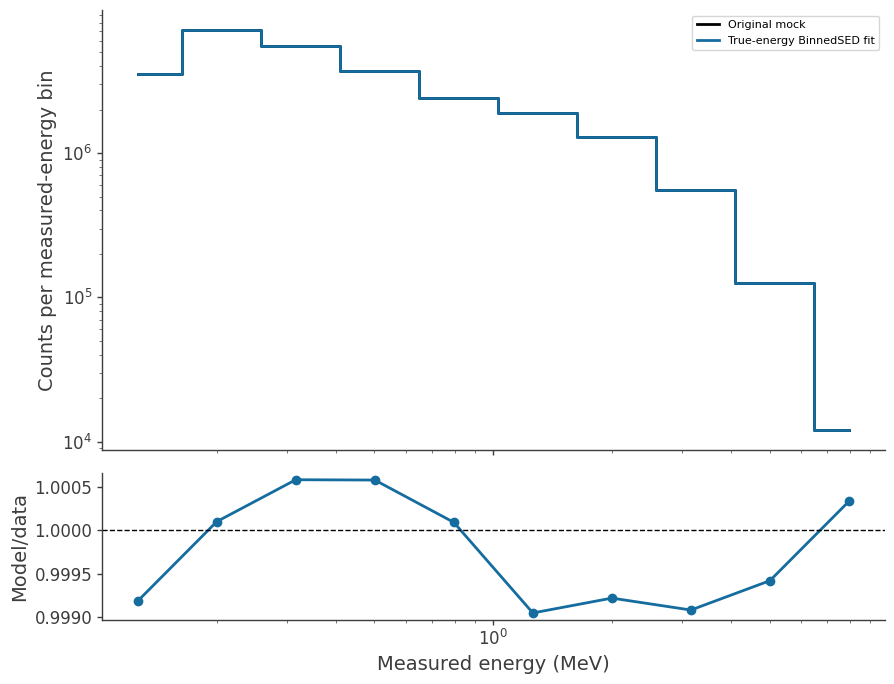

In [17]:
observed_em = np.asarray(best_fit["record"]["observed counts by Em"])
model_em = np.asarray(best_fit["record"]["model counts by Em"])
table = pd.DataFrame({
    "Em lower (MeV)": data_hist.axes["Em"].edges[:-1].to_value(u.MeV),
    "Em upper (MeV)": data_hist.axes["Em"].edges[1:].to_value(u.MeV),
    "observed counts": observed_em, "model counts": model_em,
    "model / observed": np.divide(model_em, observed_em,
                                  out=np.full_like(model_em, np.nan),
                                  where=observed_em > 0),
})
display(table)
fig, (ax, ratio_ax) = plt.subplots(
    2, 1, figsize=(9, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]},
)
centers = np.sqrt(table["Em lower (MeV)"] * table["Em upper (MeV)"])
ax.step(centers, observed_em, where="mid", label="Original mock", color="black")
ax.step(centers, model_em, where="mid", label="True-energy BinnedSED fit", color="#146c9f")
ax.set(xscale="log", yscale="log", ylabel="Counts per measured-energy bin")
ax.legend()
ratio_ax.plot(centers, table["model / observed"], "o-", color="#146c9f")
ratio_ax.axhline(1., color="black", lw=1, ls="--")
ratio_ax.set(xscale="log", xlabel="Measured energy (MeV)", ylabel="Model/data")
fig.tight_layout()
plt.show()

## Figure 1: NGC 4151 energy spectrum

The SC curve below uses the best **true-energy BinnedSED nuisance fit**.
Its local 68% band includes covariance with all 15 source-bin amplitudes
and instrumental background. The two comparison curves and their existing
bands are loaded from the earlier notebook only after verifying that they
describe the same original mock, GTI and response. They do not require a
new fit. The independent SC SED is recomputed with the true-energy nuisance
model; the old detector-bin SED is never reused.

Run the setup and template cells first. If the saved 19-parameter fit JSON
is present, this section can run without repeating the multi-start fit.

In [18]:
# Local Fisher band only: a Gaussian approximation, not a bounded profile interval.
from dataclasses import dataclass
from scipy.optimize import brentq, minimize
from astromodels import Powerlaw, Uniform_prior
from threeML import BayesianAnalysis
import matplotlib.ticker as mticker
if str(notebook_dir) not in sys.path:
    sys.path.insert(0, str(notebook_dir))
from agn_paper_plot_style import BLUE, GREEN, ink, paper_style, style_axis

plot_dir = notebook_dir / "plots"
fit_path = plot_dir / "NGC4151_DC4_original_mock_trueEi_BinnedSED_standard_COSIpy_SciPy.json"
fit_saved = json.loads(fit_path.read_text())
if (fit_saved["fixed cache key"] != fixed_cache_key
        or fit_saved["true template cache key"] != true_cache_key
        or fit_saved["data"] != str(mock_data_path)
        or fit_saved["catalog"] != str(parallel_catalog_path)):
    raise RuntimeError("Saved true-energy fit does not match these inputs and templates")
best_record = max((row for row in fit_saved["starts"] if row.get("success")),
                  key=lambda row: row["log likelihood"])
print("Plotting true-energy fit from start:", best_record["start"])

old_bands_path = plot_dir / "NGC4151_DC4_original_mock_binwise_68_bands_below_1MeV.json"
comparison_bands = json.loads(old_bands_path.read_text())
if comparison_bands["template cache key"] != fixed_cache_key:
    raise RuntimeError("No SC / isolated bands describe a different GTI or response")
no_sc_record = json.loads((plot_dir / "NGC4151_DC4_paper_full_mock_no_catalog_comparison.json").read_text())
isolated_record = json.loads((plot_dir / "NGC4151_DC4_paper_isolated_cpl_original_fits_3months.json").read_text())
if no_sc_record["source data file"] != str(mock_data_path.resolve()):
    raise RuntimeError("No SC fit uses different full-mock data")
isolated_path = Path(isolated_record["source data file"])
if isolated_record["exposure months"] != 3 or not isolated_path.name.startswith("NGC_4151_3months"):
    raise RuntimeError("The isolated comparison is not the original three-month NGC fit")

pivot_keV = float(parallel_model.ngc4151.spectrum.main.composite.piv_1.value)
fitted_shape = Cutoff_powerlaw(
    K=best_record["NGC K"], piv=pivot_keV,
    index=best_record["NGC index"], xc=best_record["NGC xc keV"],
)
source_position = parallel_model.ngc4151.position
fitted_point = PointSource(
    "ngc4151", l=source_position.l.value, b=source_position.b.value,
    spectral_shape=fitted_shape,
)
ngc_response = point_responses.get("ngc4151", psr).copy()
ngc_response.set_source(fitted_point)

def ngc_detector_counts(trial):
    """Detector expectation for (log K, index, log cutoff in keV)."""
    fitted_shape.K.value = float(np.exp(trial[0]))
    fitted_shape.index.value = float(trial[1])
    fitted_shape.xc.value = float(np.exp(trial[2]))
    return dense_counts(ngc_response.expectation(copy=False)).reshape(observed_counts.shape)

cpl_best_x = np.array([
    np.log(best_record["NGC K"]), best_record["NGC index"],
    np.log(best_record["NGC xc keV"]),
])
ngc_best_counts = ngc_detector_counts(cpl_best_x)
source_scales = np.asarray([
    best_record["true-energy source scales"][name]
    for name in NUISANCE_SOURCES
], dtype=float)
fitted_other_sky = fixed_plus_high + np.einsum(
    "se,seij->ij", source_scales, ei_templates, optimize=True,
)
fitted_bkg = best_record["background Hz"] / background_rate_initial * bkg_counts
model_counts = fitted_other_sky + fitted_bkg + ngc_best_counts
if not np.allclose(model_counts.sum(axis=1), best_record["model counts by Em"], rtol=1e-8):
    raise RuntimeError("Saved fit and recomputed detector expectation differ")

def response_derivative(function, x, i, step=2e-4):
    plus, minus = x.copy(), x.copy()
    plus[i] += step
    minus[i] -= step
    return (function(plus) - function(minus)) / (2. * step)

# Parameter order: log K, index, log cutoff, background rate scale,
# then five true-energy scales for each of the three nuisance sources.
jac = [response_derivative(ngc_detector_counts, cpl_best_x, i)
       for i in range(3)]
jac.append(bkg_counts)
jac.extend(ei_templates.reshape(15, *observed_counts.shape))
weighted = np.asarray(jac).reshape(19, -1) / np.sqrt(model_counts.ravel())[None, :]
fisher = weighted @ weighted.T
norms = np.sqrt(np.diag(fisher))
correlation = fisher / np.outer(norms, norms)
eigenvalues = np.linalg.eigvalsh(correlation)
if not np.all(np.isfinite(eigenvalues)) or eigenvalues[0] <= 0:
    raise RuntimeError("True-energy Fisher matrix is not positive definite")
covariance = np.linalg.solve(correlation, np.diag(1. / norms)) / norms[:, None]
covariance = 0.5 * (covariance + covariance.T)
print("Fisher condition number:", float(eigenvalues[-1] / eigenvalues[0]))

energy_band_keV = np.asarray(comparison_bands["energy keV"], dtype=float)
cpl_best = (best_record["NGC K"] * (energy_band_keV / pivot_keV)**best_record["NGC index"]
            * np.exp(-energy_band_keV / best_record["NGC xc keV"]))
log_flux_gradient = np.stack([
    np.ones_like(energy_band_keV),
    np.log(energy_band_keV / pivot_keV),
    energy_band_keV / best_record["NGC xc keV"],
])
log_flux_variance = np.einsum(
    "ie,ij,je->e", log_flux_gradient, covariance[:3, :3], log_flux_gradient,
)
if np.any(log_flux_variance < -1e-10):
    raise RuntimeError("Negative propagated log-flux variance")
log_flux_sigma = np.sqrt(np.maximum(log_flux_variance, 0.))
sc_band = {
    "best": cpl_best.tolist(),
    "low": (cpl_best * np.exp(-log_flux_sigma)).tolist(),
    "high": (cpl_best * np.exp(log_flux_sigma)).tolist(),
    "CPL covariance": covariance[:3, :3].tolist(),
}
band_path = plot_dir / "NGC4151_DC4_original_mock_trueEi_BinnedSED_68_band.json"
band_path.write_text(json.dumps({
    "method": "local expected Poisson Fisher, all 19 parameters; 68% log-flux",
    "fixed cache key": fixed_cache_key,
    "true template cache key": true_cache_key,
    "fit log likelihood": best_record["log likelihood"],
    "energy keV": energy_band_keV.tolist(),
    "SC": sc_band,
}, indent=2) + "\n")
print("Saved", band_path)


Plotting true-energy fit from start: reference_start


Fisher condition number: 7069.281943595073
Saved /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_DC4_original_mock_trueEi_BinnedSED_68_band.json


### Independent ten-bin SED

These SED points fit NGC 4151 independently in all ten native incident
energy bins, using `BinnedSED`'s default fixed photon index −2 within
each bin. The true-energy nuisance sources remain at their best-fit
amplitudes. As in the reference notebook, TS < 1 upper limits use a
threeML Bayesian posterior; other limits use a likelihood profile.
The SED is cached so the figure can be rerun without repeating the profiles.

In [19]:
# Independent SED: all ten native Ei amplitudes are fitted jointly.
# Each bin uses BinnedSED's default fixed E^-2 photon index.
def _dense_counts(histogram):
    values = histogram.to_dense(copy=False).contents
    if hasattr(values, "compute"):
        values = values.compute()
    if hasattr(values, "value"):
        values = values.value
    return np.asarray(values, dtype=float).copy()

@dataclass
class JointSEDFitResult:
    k: np.ndarray
    scaled_k: np.ndarray
    relative_nll: float
    ts: np.ndarray | None = None
    lower68: np.ndarray | None = None
    upper68: np.ndarray | None = None
    upper95: np.ndarray | None = None


class JointSEDTemplates:
    def __init__(self, background, probe_templates, probe_k, max_k):
        self.background = np.asarray(background, dtype=float).ravel()
        templates = np.asarray(probe_templates, dtype=float)
        self.probe_k = np.asarray(probe_k, dtype=float)
        self.max_k = np.asarray(max_k, dtype=float)
        if templates.ndim < 2 or templates.shape[0] != len(self.probe_k):
            raise ValueError("One detector template is required for each SED bin.")
        self.templates = templates.reshape(len(self.probe_k), -1)
        if self.templates.shape[1] != self.background.size:
            raise ValueError("Templates and background have different detector cells.")
        invalid = []
        for name, counts in (("fixed sky + instrumental background", self.background),
                             ("NGC 4151 SED templates", self.templates)):
            n_nonfinite = int(np.count_nonzero(~np.isfinite(counts)))
            n_negative = int(np.count_nonzero(counts < 0))
            if n_nonfinite or n_negative:
                invalid.append(f"{name}: {n_nonfinite} nonfinite, {n_negative} negative")
        if invalid:
            raise ValueError("Invalid Poisson counts: " + "; ".join(invalid))
        if np.any(self.probe_k <= 0) or np.any(self.max_k <= 0):
            raise ValueError("Probe and maximum normalizations must be positive.")
        self.probe_totals = self.templates.sum(axis=1)
        self.active_bins = np.flatnonzero(self.probe_totals > 0)
        if self.active_bins.size == 0:
            raise ValueError("No SED bin has a nonzero detector response.")
        self.k_scale = np.zeros(len(self.probe_k))
        self.k_scale[self.active_bins] = np.minimum(
            self.max_k[self.active_bins],
            self.probe_k[self.active_bins] * 10.0 / self.probe_totals[self.active_bins],
        )
        self.count_templates = self.templates[self.active_bins] * (
            self.k_scale[self.active_bins] / self.probe_k[self.active_bins]
        )[:, None]
        self.count_totals = self.count_templates.sum(axis=1)
        self.upper_scaled = self.max_k[self.active_bins] / self.k_scale[self.active_bins]

    def fit(self, data, initial_k=None, profile_ts=False, intervals=False):
        """Fit all K_i at once; optionally profile each bin's TS and limits."""
        data = np.asarray(data, dtype=float).ravel()
        if data.shape != self.background.shape or np.any(data < 0):
            raise ValueError("Data and background must match and be non-negative.")
        # Occupied cells without any SED response add only a constant to the
        # likelihood. Excluding them also avoids huge ratios from tiny empty
        # background-template cells.
        responsive = np.any(self.count_templates > 0, axis=0)
        occupied = (data > 0) & responsive
        background = self.background[occupied]
        if np.any(background <= 0):
            raise ValueError("Background must be positive in responsive data cells.")
        observed = data[occupied]
        templates = self.count_templates[:, occupied]
        totals = self.count_totals
        n_free = len(self.active_bins)
        # Keep free amplitudes just above zero during optimization. The null
        # value remains exactly zero for TS profiling. With a subnormal
        # instrumental-background floor, an optimizer trial at x=0 can give
        # a ~1e242 score and make L-BFGS-B report ABNORMAL.
        lower_scaled = np.minimum(1e-8, 1e-3 * self.upper_scaled)
        bounds = list(zip(lower_scaled, self.upper_scaled))
        if initial_k is None:
            x0 = np.ones(n_free)
        else:
            initial_k = np.asarray(initial_k, dtype=float)
            x0 = initial_k[self.active_bins] / self.k_scale[self.active_bins]
            x0 = np.clip(x0, lower_scaled, self.upper_scaled)
        # The probe scaling targets roughly ten counts per active bin. Avoid
        # starting all bins at zero when the preceding global CPL fit is weak.
        x0 = np.maximum(x0, np.minimum(1.0, self.upper_scaled))
        reference = background + x0 @ templates
        if np.any(reference <= 0) or np.any(~np.isfinite(reference)):
            raise ValueError("The initial SED model has invalid Poisson expectations.")
        log_reference = np.log(reference)

        def objective(x):
            source = x @ templates
            expected = background + source
            if np.any(expected <= 0) or np.any(~np.isfinite(expected)):
                return np.inf, np.full(n_free, np.nan)
            # log(expected)-log(reference) stays finite when the background
            # is subnormal. log1p(source/background) can overflow to infinity.
            value = float(totals @ x - observed @ (np.log(expected) - log_reference))
            ratio = observed / np.maximum(expected, 1e-250)
            gradient = totals - templates @ ratio
            return value, gradient

        optimum = minimize(
            objective, x0, method="L-BFGS-B", jac=True, bounds=bounds,
            options={"maxiter": 2000, "ftol": 1e-12, "gtol": 1e-6},
        )
        if not optimum.success or not np.isfinite(optimum.fun):
            retry_start = np.minimum(np.ones(n_free), self.upper_scaled)
            optimum = minimize(
                objective, retry_start, method="L-BFGS-B", jac=True, bounds=bounds,
                options={"maxiter": 5000, "maxls": 80, "ftol": 1e-12, "gtol": 1e-7},
            )
        if not optimum.success or not np.isfinite(optimum.fun):
            raise RuntimeError(
                f"Joint BinnedSED fit failed: {optimum.message}; "
                f"active bins={self.active_bins.tolist()}, "
                f"probe totals={self.probe_totals.tolist()}"
            )
        best = np.asarray(optimum.x, dtype=float)
        best_nll = float(objective(best)[0])
        k = np.zeros(len(self.probe_k))
        k[self.active_bins] = best * self.k_scale[self.active_bins]
        result = JointSEDFitResult(k=k, scaled_k=best, relative_nll=best_nll)
        if not profile_ts and not intervals:
            return result

        def profile_nll(local_index, fixed_value):
            if fixed_value == best[local_index]:
                return best_nll
            other = np.arange(n_free) != local_index
            trial = best.copy()
            trial[local_index] = fixed_value
            if not np.any(other):
                return float(objective(trial)[0])

            def other_objective(values):
                trial[other] = values
                value, gradient = objective(trial)
                return value, gradient[other]

            profiled = minimize(
                other_objective, best[other], method="L-BFGS-B", jac=True,
                bounds=[bounds[i] for i in np.flatnonzero(other)],
                options={"maxiter": 500, "ftol": 1e-12, "gtol": 1e-6},
            )
            if not profiled.success:
                profiled = minimize(
                    other_objective, profiled.x, method="SLSQP", jac=True,
                    bounds=[bounds[i] for i in np.flatnonzero(other)],
                    options={"maxiter": 500, "ftol": 1e-9},
                )
            if not profiled.success or not np.isfinite(profiled.fun):
                raise RuntimeError(f"SED bin {local_index} profile failed: {profiled.message}")
            return float(profiled.fun)

        ts = np.zeros(len(self.probe_k))
        lower68 = np.zeros(len(self.probe_k))
        upper68 = np.full(len(self.probe_k), np.nan)
        upper95 = np.full(len(self.probe_k), np.nan)
        for j, bin_index in enumerate(self.active_bins):
            null_nll = profile_nll(j, 0.0)
            ts[bin_index] = max(0.0, 2.0 * (null_nll - best_nll))
            if not intervals:
                continue

            def delta(value):
                return max(0.0, 2.0 * (profile_nll(j, value) - best_nll))

            if best[j] > 0 and ts[bin_index] > 1.0:
                lower_scaled = brentq(
                    lambda value: delta(value) - 1.0, 0.0, best[j],
                    xtol=1e-8, rtol=1e-7,
                )
                lower68[bin_index] = lower_scaled * self.k_scale[bin_index]

            def upper_root(target):
                lo = best[j]
                hi = min(self.upper_scaled[j], max(lo + 1.0, lo * 2.0))
                while delta(hi) < target and hi < self.upper_scaled[j]:
                    hi = min(self.upper_scaled[j], hi * 2.0)
                if delta(hi) < target:
                    return float("nan")
                return brentq(
                    lambda value: delta(value) - target, lo, hi,
                    xtol=1e-8, rtol=1e-7,
                ) * self.k_scale[bin_index]

            upper68[bin_index] = upper_root(1.0)
            upper95[bin_index] = upper_root(2.705543)
        result.ts = ts
        if intervals:
            result.lower68 = lower68
            result.upper68 = upper68
            result.upper95 = upper95
        return result

class WeakBinPoissonLike(PluginPrototype):
    """Precomputed detector-count likelihood for one weak SED-bin amplitude."""
    def __init__(self, name, base_counts, source_counts, observed, amplitude_parameter, total_source_counts):
        super().__init__(name, {})
        self.base = np.asarray(base_counts, dtype=float)
        self.template = np.asarray(source_counts, dtype=float)
        self.data = np.asarray(observed, dtype=float)
        self.amplitude_parameter = amplitude_parameter
        if np.any(self.base <= 0) or np.any(self.template < 0):
            raise ValueError("Invalid Bayesian Poisson template")
        self.reference = np.log(self.base + self.template)
        self.total_template = float(total_source_counts)

    def set_model(self, likelihood_model):
        self._likelihood_model = likelihood_model

    def get_log_like(self):
        x = float(self.amplitude_parameter.value)
        if x < 0:
            return -np.inf
        expected = self.base + x * self.template
        if np.any(expected <= 0) or np.any(~np.isfinite(expected)):
            return -np.inf
        # Constant terms cancel; nonresponsive occupied cells are omitted.
        return float(self.data @ (np.log(expected) - self.reference)
                     - x * self.total_template)

    def inner_fit(self):
        return self.get_log_like()

    def get_number_of_data_points(self):
        return int(self.data.size)


def bayesian_weak_limits(template_fit, fit_result, observed_hist, *, label):
    """Replace only TS<1 profile ULs with 95% threeML posterior quantiles."""
    observed = _dense_counts(observed_hist).ravel()
    active = template_fit.active_bins
    responsive = np.any(template_fit.count_templates > 0, axis=0)
    occupied = (observed > 0) & responsive
    count_templates = template_fit.count_templates[:, occupied]
    best = fit_result.scaled_k.copy()
    bayes_ul = np.full(len(template_fit.probe_k), np.nan)
    diagnostics = []
    for j, bin_index in enumerate(active):
        if fit_result.ts[bin_index] >= 1.0:
            continue
        source_all = count_templates[j]
        relevant = source_all > 0
        if not np.any(relevant):
            continue
        source = source_all[relevant]
        # Form the other-bin model directly. Subtracting one tiny component
        # from a large baseline can cancel the subnormal background to zero.
        other = np.arange(len(active)) != j
        base = (template_fit.background[occupied][relevant]
                + best[other] @ count_templates[other][:, relevant])
        if np.any(base <= 0):
            raise RuntimeError(f"{label}: nonpositive baseline in weak SED bin {bin_index+1}")
        profile_ul = fit_result.upper95[bin_index]
        scaled_profile = profile_ul / template_fit.k_scale[bin_index] if np.isfinite(profile_ul) else 0.
        prior_max = min(template_fit.upper_scaled[j], max(30., 20. * scaled_profile, 20. * best[j]))
        if not np.isfinite(prior_max) or prior_max <= 0:
            raise RuntimeError(f"{label}: invalid prior bound in SED bin {bin_index+1}")
        dummy = PointSource(f"weak_bin_{bin_index+1}", l=0., b=0.,
                            spectral_shape=Powerlaw(K=min(1., prior_max/2.),
                                                    piv=1000., index=-2.))
        posterior_model = Model(dummy)
        amplitude = posterior_model.point_sources[dummy.name].spectrum.main.Powerlaw.K
        for par in dummy.parameters.values():
            par.fix = True
        amplitude.fix = False
        # Powerlaw.K has a logarithmic transform in astromodels and therefore
        # needs a strictly positive numerical minimum. The uniform prior
        # still starts at zero; this 1e-12 floor has negligible mass.
        amplitude.min_value, amplitude.max_value = max(1e-12, 1e-12*prior_max), float(prior_max)
        amplitude.prior = Uniform_prior(lower_bound=0., upper_bound=float(prior_max))
        plugin = WeakBinPoissonLike(
            f"weak_bin_like_{bin_index+1}", base, source,
            observed[occupied][relevant], amplitude,
            total_source_counts=template_fit.count_totals[j],
        )
        analysis = BayesianAnalysis(posterior_model, DataList(plugin))
        analysis.set_sampler("emcee")
        analysis.sampler.setup(n_walkers=20, n_iterations=1800, n_burn_in=600,
                               seed=1400 + bin_index)
        analysis.sample(quiet=True)
        draws = np.asarray(analysis.samples[amplitude.path], dtype=float)
        q95 = float(np.quantile(draws, 0.95))
        if not np.isfinite(q95) or q95 >= 0.9 * prior_max:
            raise RuntimeError(f"{label}: weak-bin posterior hits its prior bound in bin {bin_index+1}")
        bayes_ul[bin_index] = q95 * template_fit.k_scale[bin_index]
        diagnostics.append(dict(bin=int(bin_index+1), TS=float(fit_result.ts[bin_index]),
                                prior_max_K=float(prior_max * template_fit.k_scale[bin_index]),
                                upper95_K=float(bayes_ul[bin_index]),
                                draws=int(draws.size)))
        print(f"{label} SED bin {bin_index+1}: TS={fit_result.ts[bin_index]:.2f}, "
              f"Bayesian 95% K UL={bayes_ul[bin_index]:.4g}")
    return bayes_ul, diagnostics

In [20]:
sed_path = plot_dir / "NGC4151_DC4_original_mock_trueEi_BinnedSED_independent_sed.json"
if sed_path.exists():
    cached_sed = json.loads(sed_path.read_text())
else:
    cached_sed = None
if (cached_sed is not None
        and cached_sed.get("true template cache key") == true_cache_key
        and cached_sed.get("fit log likelihood") == best_record["log likelihood"]):
    sed_result = cached_sed
    print("Loaded independent SED:", sed_path)
else:
    ei_edges = dr.axes["Ei"].edges.to_value(u.keV)
    ei_pivots = np.sqrt(ei_edges[:-1] * ei_edges[1:])
    initial_k = (best_record["NGC K"] * (ei_pivots / pivot_keV)**best_record["NGC index"]
                 * np.exp(-ei_pivots / best_record["NGC xc keV"]))
    sed = BinnedSED.from_response(dr, initial_fluxes=initial_k)
    if not np.isclose(sed.spectral_shape.index.value, -2.):
        raise RuntimeError("Expected BinnedSED default photon index -2")
    sed_point = PointSource(
        "ngc4151", l=source_position.l.value, b=source_position.b.value,
        spectral_shape=sed,
    )
    sed_shape = sed_point.spectrum.main.shape
    for parameter in sed_shape.normalizations:
        parameter.value = 0.
        parameter.fix = True
    sed_response = point_responses.get("ngc4151", psr).copy()
    sed_response.set_source(sed_point)
    max_k = np.asarray([p.max_value for p in sed_shape.normalizations], dtype=float)
    probe_k = np.minimum(max_k, np.maximum(initial_k, 1e-5))
    templates = []
    for i, parameter in enumerate(sed_shape.normalizations):
        parameter.value = float(probe_k[i])
        templates.append(np.maximum(
            dense_counts(sed_response.expectation(copy=False)).reshape(observed_counts.shape), 0.
        ))
        parameter.value = 0.
    fixed_sed_counts = fitted_other_sky + fitted_bkg
    template_fit = JointSEDTemplates(fixed_sed_counts, np.stack(templates), probe_k, max_k)
    fitted = template_fit.fit(observed_counts, initial_k=initial_k,
                              profile_ts=True, intervals=True)
    bayes_ul, diagnostics = bayesian_weak_limits(
        template_fit, fitted, data_hist, label="true-energy SC")
    upper95 = fitted.upper95.copy()
    weak = fitted.ts < 1.
    upper95[weak & np.isfinite(bayes_ul)] = bayes_ul[weak & np.isfinite(bayes_ul)]
    sed_result = {
        "true template cache key": true_cache_key,
        "fit log likelihood": best_record["log likelihood"],
        "spectral shape": "Powerlaw(index=-2)",
        "edges keV": ei_edges.tolist(), "pivot keV": ei_pivots.tolist(),
        "K": fitted.k.tolist(), "TS": fitted.ts.tolist(),
        "lower 68": fitted.lower68.tolist(), "upper 68": fitted.upper68.tolist(),
        "upper 95": upper95.tolist(),
        "upper limit method": [
            "Bayesian 95%" if weak[i] and np.isfinite(bayes_ul[i]) else "profile 95%"
            for i in range(len(ei_pivots))
        ],
        "bayesian diagnostics": diagnostics,
    }
    sed_path.write_text(json.dumps(sed_result, indent=2) + "\n")
    print("Saved", sed_path)
display(pd.DataFrame({k: sed_result[k] for k in
                      ("pivot keV", "K", "TS", "lower 68", "upper 68", "upper 95", "upper limit method")}))

Loaded independent SED: /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_DC4_original_mock_trueEi_BinnedSED_independent_sed.json


,pivot keV,K,TS,lower 68,upper 68,upper 95,upper limit method
0,125.892414,1.757020e-05,68.291914,1.543509e-05,1.970710e-05,2.108600e-05,profile 95%
1,199.526172,4.521520e-06,93.024150,4.051270e-06,4.992197e-06,5.295815e-06,profile 95%
2,316.227923,9.175356e-07,25.647981,7.361034e-07,1.099049e-06,1.216167e-06,profile 95%
3,501.186989,1.098664e-07,1.411602,1.738677e-08,2.024339e-07,2.621659e-07,profile 95%
4,794.328018,3.970842e-18,0.000000,0.000000e+00,3.827695e-08,8.880110e-08,Bayesian 95%
5,1258.924144,1.935128e-08,0.294981,0.000000e+00,5.502520e-08,8.525883e-08,Bayesian 95%
6,1995.261723,1.447490e-08,0.316491,0.000000e+00,3.965200e-08,5.922795e-08,Bayesian 95%
7,3162.279229,2.582192e-10,0.000127,0.000000e+00,2.385886e-08,4.535125e-08,Bayesian 95%
8,5011.869895,2.060128e-18,0.000000,0.000000e+00,7.610836e-09,2.676261e-08,Bayesian 95%
9,7943.280179,2.337650e-18,0.000000,0.000000e+00,2.023406e-09,8.250786e-09,Bayesian 95%


### White-background spectrum comparison

The blue SC curve and SED are recalculated for this true-energy fit.
The green No SC and red isolated NGC 4151 curves reproduce the same
three-month reference comparisons used in the earlier paper figure.

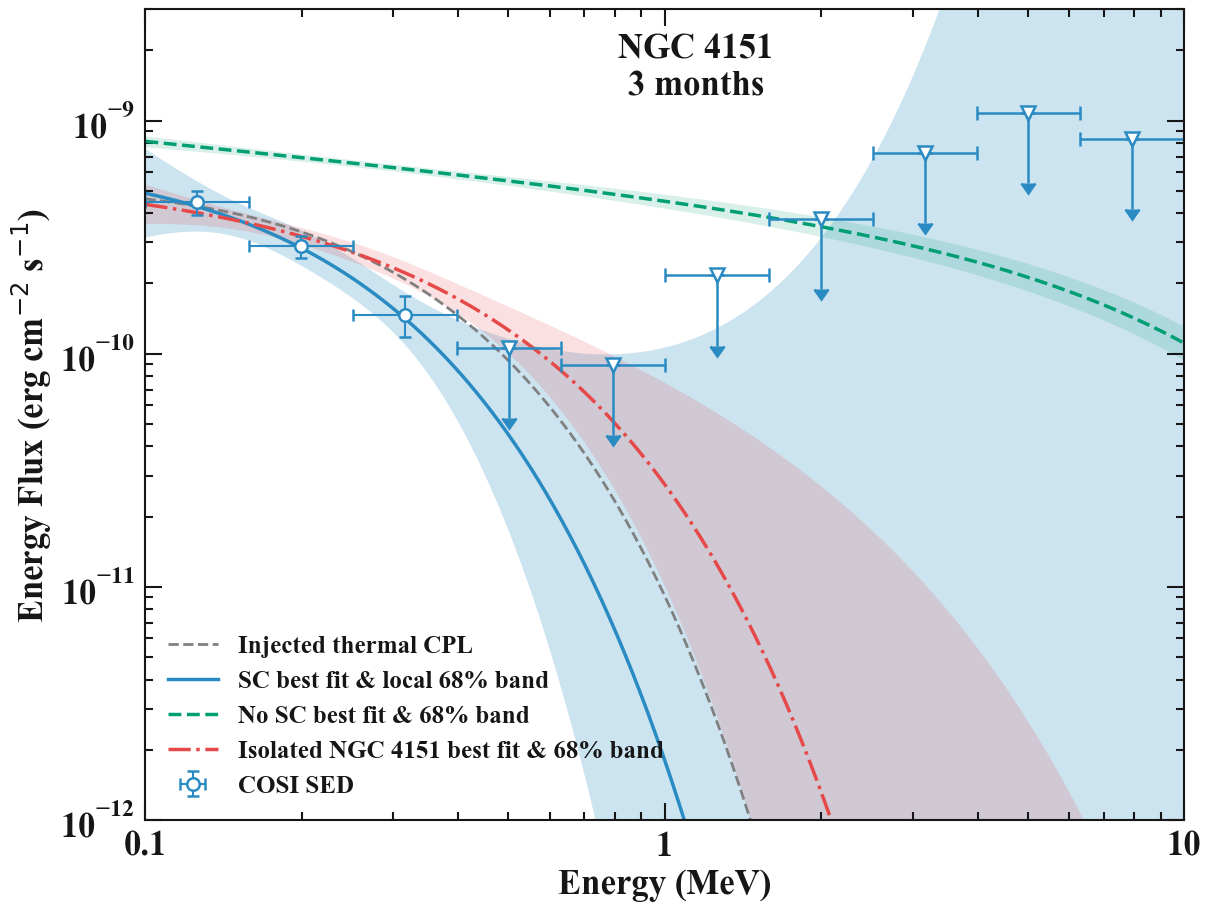

Saved /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_DC4_original_mock_trueEi_BinnedSED_SC_Figure1_white.pdf and /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_DC4_original_mock_trueEi_BinnedSED_SC_Figure1_white.png


In [21]:
e_keV = energy_band_keV
x_mev = e_keV / 1000.
keV_to_erg = u.keV.to(u.erg)
injected_thermal = 0.15 * e_keV**(-1.75) * np.exp(-e_keV / 200.)

def energy_flux(values):
    return keV_to_erg * e_keV**2 * np.asarray(values, dtype=float)

sed_pivot = np.asarray(sed_result["pivot keV"], dtype=float)
sed_edges = np.asarray(sed_result["edges keV"], dtype=float)
sed_k = np.asarray(sed_result["K"], dtype=float)
sed_ts = np.asarray(sed_result["TS"], dtype=float)
sed_low = np.asarray(sed_result["lower 68"], dtype=float)
sed_high = np.asarray(sed_result["upper 68"], dtype=float)
sed_ul = np.asarray(sed_result["upper 95"], dtype=float)
detected = ((sed_ts >= 4.) & (sed_k > 0.) & (sed_low > 0.)
            & np.isfinite(sed_high) & (sed_high > sed_k))
upper = (~detected) & np.isfinite(sed_ul) & (sed_ul > 0.)

with paper_style("light", font_size=25):
    fig, ax = plt.subplots(figsize=(12, 9), constrained_layout=True)
    style_axis(ax, "light", 25)
    ax.plot(x_mev, energy_flux(injected_thermal), color="0.50", ls="--", lw=2,
            label="Injected thermal CPL")
    for curve, color, linestyle, label, alpha in (
        (sc_band, BLUE, "-", "SC best fit & local 68% band", 0.24),
        (comparison_bands["no_sc"], GREEN, "--", "No SC best fit & 68% band", 0.15),
        (comparison_bands["isolated"], "#E64949", "-.",
         "Isolated NGC 4151 best fit & 68% band", 0.17),
    ):
        ax.plot(x_mev, energy_flux(curve["best"]), color=color, ls=linestyle,
                lw=2.5, label=label)
        ax.fill_between(x_mev, energy_flux(curve["low"]),
                        energy_flux(curve["high"]), color=color, alpha=alpha,
                        linewidth=0)
    if np.any(detected):
        p, k = sed_pivot[detected], sed_k[detected]
        ax.errorbar(p / 1000., keV_to_erg * p**2 * k,
                    xerr=np.vstack((p - sed_edges[:-1][detected],
                                    sed_edges[1:][detected] - p)) / 1000.,
                    yerr=np.vstack((keV_to_erg * p**2 * (k - sed_low[detected]),
                                    keV_to_erg * p**2 * (sed_high[detected] - k))),
                    fmt="o", color=BLUE, ecolor=BLUE, markerfacecolor="white",
                    markeredgewidth=1.8, markersize=9, capsize=4, elinewidth=1.5,
                    label="COSI SED")
    if np.any(upper):
        p = sed_pivot[upper]
        limit = keV_to_erg * p**2 * sed_ul[upper]
        ax.errorbar(p / 1000., limit,
                    xerr=np.vstack((p - sed_edges[:-1][upper],
                                    sed_edges[1:][upper] - p)) / 1000.,
                    yerr=np.maximum(0.5 * limit, np.finfo(float).tiny),
                    uplims=True, fmt="v", color=BLUE, markerfacecolor="white",
                    markeredgewidth=1.8, markersize=10, capsize=5, elinewidth=1.8)
    visible = np.r_[keV_to_erg * sed_pivot[detected]**2 * sed_k[detected],
                    keV_to_erg * sed_pivot[upper]**2 * sed_ul[upper]]
    y_min = min(1e-12, 0.35 * np.min(visible)) if visible.size else 1e-13
    y_max = max(3e-9, 2. * np.max(visible)) if visible.size else 3e-9
    ax.set(xscale="log", yscale="log", xlim=(0.1, 10.), ylim=(y_min, y_max),
           xlabel="Energy (MeV)",
           ylabel=r"Energy Flux (erg cm$^{-2}$ s$^{-1}$)")
    ax.xaxis.set_major_locator(mticker.FixedLocator([0.1, 1., 10.]))
    ax.xaxis.set_major_formatter(mticker.FixedFormatter(["0.1", "1", "10"]))
    ax.text(0.53, 0.97, "NGC 4151\n3 months", transform=ax.transAxes,
            ha="center", va="top", fontsize=25, color=ink("light"),
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.78, pad=5))
    ax.legend(loc="lower left", frameon=False, fontsize=18)
    pdf_path = plot_dir / "NGC4151_DC4_original_mock_trueEi_BinnedSED_SC_Figure1_white.pdf"
    png_path = plot_dir / "NGC4151_DC4_original_mock_trueEi_BinnedSED_SC_Figure1_white.png"
    fig.savefig(pdf_path, facecolor="white", edgecolor="white", bbox_inches="tight")
    fig.savefig(png_path, dpi=220, facecolor="white", edgecolor="white", bbox_inches="tight")
    plt.show()
    print("Saved", pdf_path, "and", png_path)

## HESSE band diagnostic

This cell starts Minuit at the saved 19-parameter SciPy solution and calls **HESSE only**; it does not refit. The objective is centered to improve numerical precision, and the parameter bounds are identical to those in the fit. The blue shaded region is the **nominal pointwise 68% Gaussian curvature band** propagated from HESSE's full covariance. It is a diagnostic, not a calibrated interval when Minuit reports an invalid minimum or covariance.


08:43:15 INFO      set the minimizer to minuit                                             ]8;id=725246;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py\joint_likelihood.py]8;;\:]8;id=281336;file:///Users/parshadkp/.pyenv/versions/3.12.8/envs/cosipy312/lib/python3.12/site-packages/threeML/classicMLE/joint_likelihood.py#1017\1017]8;;\

HESSE time (s): 6.13
Valid minimum: False EDM: 1.7284463622572712
Accurate covariance: False positive definite: False
Gaussian draws outside fitted bounds: 27.0%
Saved /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_DC4_original_mock_trueEi_BinnedSED_HESSE_band.json


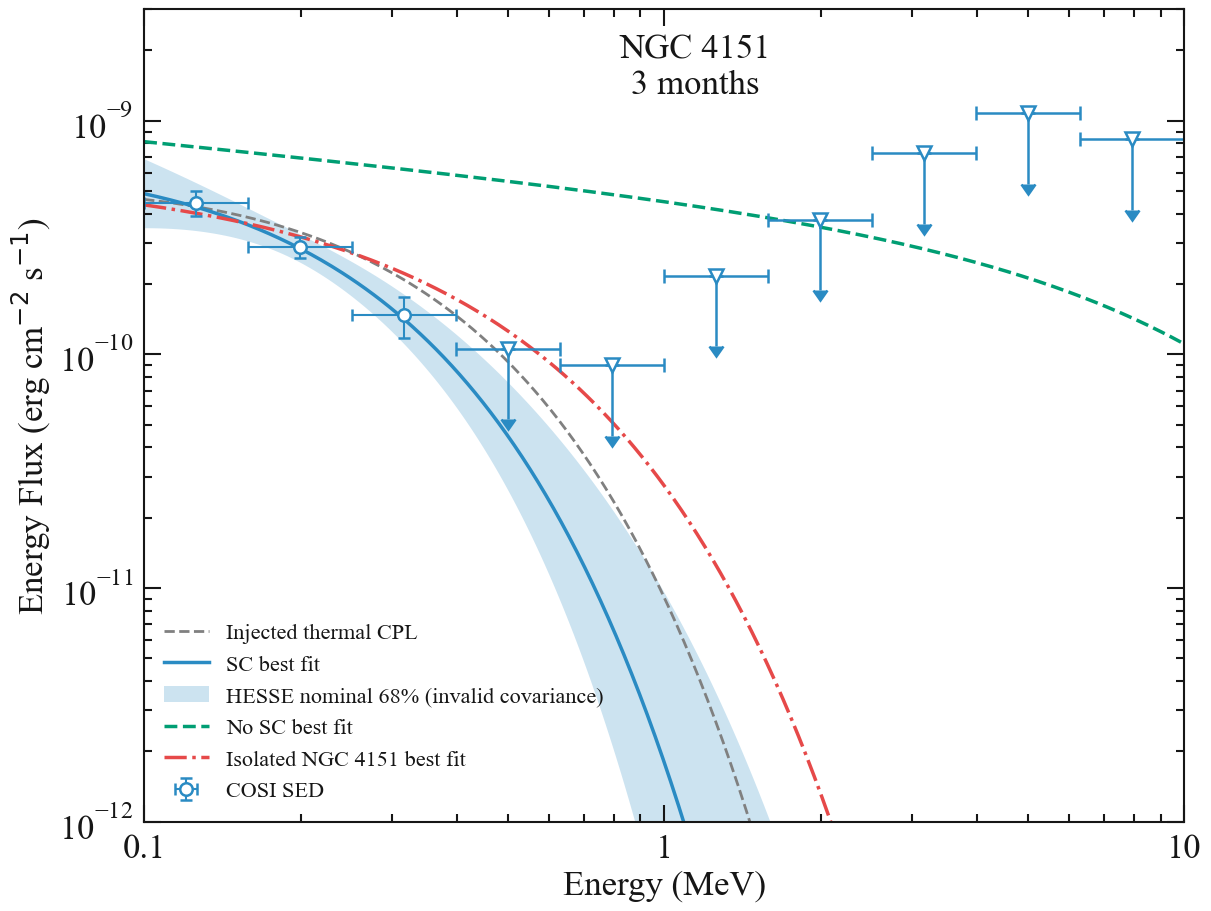

Saved /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_DC4_original_mock_trueEi_BinnedSED_SC_HESSE_diagnostic_white.pdf and /Users/parshadkp/Software/cosipy/docs/tutorials/spectral_fits/continuum_fit/AGN/plots/NGC4151_DC4_original_mock_trueEi_BinnedSED_SC_HESSE_diagnostic_white.png


In [22]:
from iminuit import Minuit

# Rebuild the standard COSIpy/threeML likelihood at the saved SciPy optimum.
# The last loop iteration above is not necessarily the best start, so do not
# reuse its JointLikelihood object.
hesse_model, hesse_baseline = make_true_energy_model()
hesse_cpl = hesse_model.ngc4151.spectrum.main.Cutoff_powerlaw
hesse_cpl.K.value = best_record["NGC K"]
hesse_cpl.index.value = best_record["NGC index"]
hesse_cpl.xc.value = best_record["NGC xc keV"]
for source_name in NUISANCE_SOURCES:
    anchor_name = "nebula" if source_name == "crab" else "main"
    anchor = hesse_model.sources[source_name].components[anchor_name].shape
    for ei_index, scale in zip(low_ei_bins,
                               best_record["true-energy source scales"][source_name]):
        anchor.normalizations[ei_index].value *= float(scale)
hesse_plugin, _, _ = make_standard_cosipy_fit(hesse_model, hesse_baseline)
hesse_plugin.bkg_parameter["instrumental"].value = best_record["background Hz"]
hesse_joint = JointLikelihood(
    hesse_model, DataList(hesse_plugin), verbose=False, record=False,
)
hesse_parameters = list(hesse_joint._free_parameters.values())
if len(hesse_parameters) != 19:
    raise RuntimeError(f"Expected 19 free parameters, found {len(hesse_parameters)}")
parameter_paths = [parameter.path for parameter in hesse_parameters]
expected_cpl_paths = [
    "ngc4151.spectrum.main.Cutoff_powerlaw.K",
    "ngc4151.spectrum.main.Cutoff_powerlaw.index",
    "ngc4151.spectrum.main.Cutoff_powerlaw.xc",
]
if parameter_paths[:3] != expected_cpl_paths:
    raise RuntimeError("Unexpected CPL parameter order; review HESSE band gradient")
internal_best = np.array([p._get_internal_value() for p in hesse_parameters])
if not (np.isclose(internal_best[0], np.log10(best_record["NGC K"]))
        and np.isclose(internal_best[2], np.log10(best_record["NGC xc keV"]))):
    raise RuntimeError("CPL K/xc internal transforms are not log10 as expected")

# Minuit HESSE can evaluate curvature at an external optimizer's solution.
# Centering subtracts a constant from -log L and does not alter its curvature.
reference_nll = hesse_joint.minus_log_like_profile(*internal_best)
def centered_negative_log_likelihood(*trial):
    return hesse_joint.minus_log_like_profile(*trial) - reference_nll

hesse_minuit = Minuit(
    centered_negative_log_likelihood, *internal_best,
    name=[f"parameter_{i}" for i in range(len(hesse_parameters))],
)
hesse_minuit.errordef = Minuit.LIKELIHOOD  # 0.5 for -log likelihood
for i, parameter in enumerate(hesse_parameters):
    hesse_minuit.limits[i] = (
        parameter._get_internal_min_value(),
        parameter._get_internal_max_value(),
    )
hesse_started = perf_counter()
hesse_minuit.hesse()
hesse_seconds = perf_counter() - hesse_started
if hesse_minuit.covariance is None:
    raise RuntimeError("HESSE did not return a covariance matrix")
hesse_covariance = np.asarray(hesse_minuit.covariance, dtype=float)
if hesse_covariance.shape != (19, 19) or not np.all(np.isfinite(hesse_covariance)):
    raise RuntimeError("HESSE covariance has the wrong shape or nonfinite entries")

# Estimate how often the Gaussian approximation leaves the fit bounds.
rng = np.random.default_rng(4151)
trial_draws = rng.multivariate_normal(internal_best, hesse_covariance, size=10000)
lower_bounds = np.array([p._get_internal_min_value() for p in hesse_parameters])
upper_bounds = np.array([p._get_internal_max_value() for p in hesse_parameters])
outside_fraction = float(np.mean(np.any(
    (trial_draws < lower_bounds) | (trial_draws > upper_bounds), axis=1,
)))
valid_hesse = bool(hesse_minuit.fmin.is_valid and
                   hesse_minuit.fmin.has_accurate_covar and
                   hesse_minuit.fmin.has_posdef_covar)
print("HESSE time (s):", round(hesse_seconds, 2))
print("Valid minimum:", bool(hesse_minuit.fmin.is_valid),
      "EDM:", float(hesse_minuit.fmin.edm))
print("Accurate covariance:", bool(hesse_minuit.fmin.has_accurate_covar),
      "positive definite:", bool(hesse_minuit.fmin.has_posdef_covar))
print("Gaussian draws outside fitted bounds:", f"{outside_fraction:.1%}")
if not valid_hesse:
    print("WARNING: The plotted HESSE envelope is diagnostic, not a validated 68% interval.")

# The first and third internal parameters are log10 K and log10 xc. The
# remaining 16 parameters enter through their covariance with these three.
log_flux_gradient_hesse = np.zeros((19, energy_band_keV.size))
log_flux_gradient_hesse[0] = np.log(10.)
log_flux_gradient_hesse[1] = np.log(energy_band_keV / pivot_keV)
log_flux_gradient_hesse[2] = (np.log(10.) * energy_band_keV /
                              best_record["NGC xc keV"])
hesse_log_variance = np.einsum(
    "ie,ij,je->e", log_flux_gradient_hesse,
    hesse_covariance, log_flux_gradient_hesse,
)
if np.any(hesse_log_variance < -1e-10):
    raise RuntimeError("HESSE produces a negative propagated flux variance")
hesse_log_sigma = np.sqrt(np.maximum(hesse_log_variance, 0.))
hesse_band = {
    "best": cpl_best.tolist(),
    "low": (cpl_best * np.exp(-hesse_log_sigma)).tolist(),
    "high": (cpl_best * np.exp(hesse_log_sigma)).tolist(),
}
hesse_result_path = plot_dir / "NGC4151_DC4_original_mock_trueEi_BinnedSED_HESSE_band.json"
hesse_result_path.write_text(json.dumps({
    "method": "iminuit HESSE at threeML SciPy solution; nominal pointwise 68%",
    "fit log likelihood": best_record["log likelihood"],
    "fixed cache key": fixed_cache_key,
    "true template cache key": true_cache_key,
    "hesse seconds": hesse_seconds,
    "valid minimum": bool(hesse_minuit.fmin.is_valid),
    "EDM": float(hesse_minuit.fmin.edm),
    "accurate covariance": bool(hesse_minuit.fmin.has_accurate_covar),
    "positive definite covariance": bool(hesse_minuit.fmin.has_posdef_covar),
    "draws outside bounds fraction": outside_fraction,
    "parameter paths": parameter_paths,
    "covariance in internal parameters": hesse_covariance.tolist(),
    "energy keV": energy_band_keV.tolist(),
    "SC": hesse_band,
}, indent=2) + "\n")
print("Saved", hesse_result_path)

# Show the same spectral comparison with the HESSE envelope in place of the
# local Fisher fill. The original Fisher-band figure remains in the cell above.
with paper_style("light", font_size=25), plt.rc_context({
    "font.weight": "normal",
    "axes.labelweight": "normal",
    "axes.titleweight": "normal",
}):
    hesse_fig, hesse_ax = plt.subplots(figsize=(12, 9), constrained_layout=True)
    style_axis(hesse_ax, "light", 25)
    hesse_ax.plot(x_mev, energy_flux(injected_thermal), color="0.50", ls="--",
                  lw=2, label="Injected thermal CPL")
    hesse_ax.plot(x_mev, energy_flux(hesse_band["best"]), color=BLUE, lw=2.5,
                  label="SC best fit")
    hesse_ax.fill_between(
        x_mev, energy_flux(hesse_band["low"]), energy_flux(hesse_band["high"]),
        color=BLUE, alpha=0.24, linewidth=0,
        label="HESSE nominal 68% (invalid covariance)" if not valid_hesse
              else "HESSE nominal 68%",
    )
    for key, color, linestyle, label in (
        ("no_sc", GREEN, "--", "No SC best fit"),
        ("isolated", "#E64949", "-.", "Isolated NGC 4151 best fit"),
    ):
        hesse_ax.plot(x_mev, energy_flux(comparison_bands[key]["best"]),
                      color=color, ls=linestyle, lw=2.5, label=label)
    if np.any(detected):
        p, k = sed_pivot[detected], sed_k[detected]
        hesse_ax.errorbar(
            p / 1000., keV_to_erg * p**2 * k,
            xerr=np.vstack((p - sed_edges[:-1][detected],
                            sed_edges[1:][detected] - p)) / 1000.,
            yerr=np.vstack((keV_to_erg * p**2 * (k - sed_low[detected]),
                            keV_to_erg * p**2 * (sed_high[detected] - k))),
            fmt="o", color=BLUE, ecolor=BLUE, markerfacecolor="white",
            markeredgewidth=1.8, markersize=9, capsize=4, elinewidth=1.5,
            label="COSI SED",
        )
    if np.any(upper):
        p = sed_pivot[upper]
        limit = keV_to_erg * p**2 * sed_ul[upper]
        hesse_ax.errorbar(
            p / 1000., limit,
            xerr=np.vstack((p - sed_edges[:-1][upper],
                            sed_edges[1:][upper] - p)) / 1000.,
            yerr=np.maximum(0.5 * limit, np.finfo(float).tiny),
            uplims=True, fmt="v", color=BLUE, markerfacecolor="white",
            markeredgewidth=1.8, markersize=10, capsize=5, elinewidth=1.8,
        )
    hesse_ax.set(xscale="log", yscale="log", xlim=(0.1, 10.),
                 ylim=(y_min, y_max), xlabel="Energy (MeV)",
                 ylabel=r"Energy Flux (erg cm$^{-2}$ s$^{-1}$)")
    hesse_ax.xaxis.set_major_locator(mticker.FixedLocator([0.1, 1., 10.]))
    hesse_ax.xaxis.set_major_formatter(mticker.FixedFormatter(["0.1", "1", "10"]))
    hesse_ax.text(0.53, 0.97, "NGC 4151\n3 months",
                  transform=hesse_ax.transAxes, ha="center", va="top",
                  fontsize=25, color=ink("light"),
                  bbox=dict(facecolor="white", edgecolor="none", alpha=0.78, pad=5))
    hesse_legend = hesse_ax.legend(loc="lower left", frameon=False, fontsize=16)
    # Keep every text artist in this figure regular weight, independent of
    # Matplotlib's installed font mapping for the shared paper style.
    for artist in (hesse_ax.xaxis.label, hesse_ax.yaxis.label,
                   *hesse_ax.get_xticklabels(), *hesse_ax.get_yticklabels(),
                   *hesse_ax.texts, *hesse_legend.get_texts()):
        artist.set_fontweight("normal")
    hesse_pdf = plot_dir / "NGC4151_DC4_original_mock_trueEi_BinnedSED_SC_HESSE_diagnostic_white.pdf"
    hesse_png = hesse_pdf.with_suffix(".png")
    hesse_fig.savefig(hesse_pdf, facecolor="white", edgecolor="white",
                      bbox_inches="tight")
    hesse_fig.savefig(hesse_png, dpi=220, facecolor="white", edgecolor="white",
                      bbox_inches="tight")
    plt.show()
    print("Saved", hesse_pdf, "and", hesse_png)
